# Limpieza de Base de Datos y Procesamiento Básico (01_base_limpia) 

El **Preprocesamiento y Limpieza de Datos** es la fase fundamental para asegurar la calidad de las series temporales satelitales y climáticas antes de aplicar cualquier modelo predictivo.

Su objetivo principal es corregir valores atípicos inducidos por anomalías atmosféricas (nubes/sombras), rellenar vacíos de información mediante interpolación y estandarizar la estructura del conjunto de datos para garantizar la integridad relacional de la información.

# Bibliotecas y estandarización 

**Homologación y Formateo Inicial**
Estandariza los nombres de todas las columnas a formato minúsculas con guiones bajos y elimina cualquier fila que no posea un identificador de parcela válido.

Justificación Teórica: La estandarización previene colisiones de variables y errores de sintaxis (Data Leakage) durante los joins (cruces) entre las fuentes satelitales y climáticas.

**En la ingeniería de datos agrícolas, mantener una llave primaria rigurosa (id_poligono) es el estándar para asegurar el rastreo espacial de los rendimientos (Perich et al., 2023)**.

In [ ]:
#Bibliotecas necesarias para el reto de agrocebada
from __future__ import annotations  #Por practica de python intermedio pero pospone la evaluación de las anotaciones
import logging #para registrar, como una sustitucion de print, se volvio necesaria por la evaluación de variables
import re
import unicodedata
from pathlib import Path
from scipy.signal import find_peaks

# Experencia en 
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
#graficas extras
import matplotlib.dates as mdates
from matplotlib.axes import Axes
from matplotlib.ticker import FuncFormatter


logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)
logger = logging.getLogger("agrocebada")
CLAVE: str = "id_poligono"
FORMATO_FECHA: str = "%d/%m/%Y"
ALIAS_CLAVE: frozenset[str] = frozenset({"id_poligon", "id_poligono", "id_parcela"})
DIR_DATOS = Path(r"<ruta-local>\DATASET_RETO_AGRO_2026")   # solo lectura
DIR_INTERIM = Path.cwd() / "data" / "interim"
DIR_INTERIM.mkdir(parents=True, exist_ok=True)
def a_snake_case(nombre: str):
    #ID_POLIGON' -> 'id_poligon', 'área_ha' -> 'area_ha'
    ascii_ = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-zA-Z]+", "_", ascii_.strip()).strip("_").lower()
#categoriza la clave y el id, trasnforma los nombres de las col. quita espacios y en mayusculas, pero conserva la geo de gdf
def estandarizar_columnas(df: pd.DataFrame):
    datos = df.rename(columns={c: a_snake_case(c) for c in df.columns})
    encontrada = [c for c in datos.columns if c in ALIAS_CLAVE]
    if len(encontrada) != 1:
        raise KeyError(f"Clave de parcela ausente o ambigua: {encontrada}")
    datos = datos.rename(columns={encontrada[0]: CLAVE})
    datos[CLAVE] = datos[CLAVE].astype("string").str.strip().str.upper()
    return datos

## Características del primer dataset

Las columnas de la tabla procesada se dividen de la siguiente manera:   **Metadatos**: (ID_POLIGONO, municipio, estado, CONJUNTO)
  
 **Objetivo:** RENDIMIENTO_T_HA

In [ ]:
# Ruta al archivo .shp 
ruta_shp = "Parcelas_Reto_AGC_CONJUNTO.shp"
gdf = gpd.read_file("<ruta-local>\\DATASET_RETO_AGRO_2026\\Parcelas_Reto_AGC_CONJUNTO_70_30\\Parcelas_Reto_AGC_CONJUNTO.shp")
print(type(gdf))

<class 'geopandas.geodataframe.GeoDataFrame'>


In [451]:
gdf

,Cultivo,ID_POLIGON,área_ha,Municipio,Estado,CONJUNTO,geometry
0,Cebada,AGC_196,8.57,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.57739 19.65802 0, -98.57751 19..."
1,Cebada,AGC_044,0.68,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58655 19.62943 0, -98.5862 19...."
2,Cebada,AGC_020,8.34,Emiliano Zapata,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.58494 19.6278 0, -98.58656 19...."
3,CEBADA,AGC_174,6.89,Cuautepec de Hinojosa,Hidalgo,PREDICCION,"POLYGON Z ((-98.30604 19.9 0, -98.30486 19.899..."
4,CEBADA,AGC_083,2.87,Cuautepec de Hinojosa,Hidalgo,ENTRENAMIENTO,"POLYGON Z ((-98.29383 19.8882 0, -98.29378 19...."
...,...,...,...,...,...,...,...
192,Cebada,AGC_074,8.54,Calpulalpan,Tlaxcala,ENTRENAMIENTO,"POLYGON Z ((-98.60778 19.52522 0, -98.60918 19..."
193,Cebada,AGC_019,5.65,Calpulalpan,Tlaxcala,ENTRENAMIENTO,"POLYGON Z ((-98.58414 19.5849 0, -98.58482 19...."
194,Cebada,AGC_103,2.48,Calpulalpan,Tlaxcala,ENTRENAMIENTO,"POLYGON Z ((-98.5847 19.58314 0, -98.58399 19...."
195,Cebada,AGC_046,7.92,Calpulalpan,Tlaxcala,ENTRENAMIENTO,"POLYGON Z ((-98.55805 19.55261 0, -98.55988 19..."


In [452]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Cultivo     197 non-null    str     
 1   ID_POLIGON  197 non-null    str     
 2   área_ha     197 non-null    float64 
 3   Municipio   197 non-null    str     
 4   Estado      197 non-null    str     
 5   CONJUNTO    197 non-null    str     
 6   geometry    197 non-null    geometry
dtypes: float64(1), geometry(1), str(5)
memory usage: 19.3 KB


**Diagnosticos generales**

In [453]:
print("\n- VALORES NULOS -")#valores nulos
print(gdf.isnull().sum())
print("\n--- FILAS DUPLICADAS ---")
print(f"Total de duplicados: {gdf.duplicated().sum()}")
print("\n--- ESTADÍSTICAS NUMÉRICAS ---")
print(gdf.describe())
print("\n--- VALORES ÚNICOS EN TEXTO ---")
for col in gdf.select_dtypes(include=['object', 'string']).columns:
    print(f"\nColumna '{col}':")
    print(gdf[col].value_counts(dropna=False))
print("\n--- VALIDACIÓN ESPACIAL ---")
print(f"¿Todas las geometrías son válidas?: {gdf.is_valid.all()}")
print(f"¿Hay geometrías vacías?: {gdf.is_empty.any()}")
print(f"Sistema de proyección (CRS): {gdf.crs}")


- VALORES NULOS -
Cultivo       0
ID_POLIGON    0
área_ha       0
Municipio     0
Estado        0
CONJUNTO      0
geometry      0
dtype: int64

--- FILAS DUPLICADAS ---
Total de duplicados: 0

--- ESTADÍSTICAS NUMÉRICAS ---
          área_ha
count  197.000000
mean     6.604315
std      7.437631
min      0.350000
25%      2.300000
50%      5.460000
75%      8.090000
max     64.300000

--- VALORES ÚNICOS EN TEXTO ---

Columna 'Cultivo':
Cultivo
CEBADA    147
Cebada     50
Name: count, dtype: int64

Columna 'ID_POLIGON':
ID_POLIGON
AGC_196    1
AGC_044    1
AGC_020    1
AGC_174    1
AGC_083    1
          ..
AGC_074    1
AGC_019    1
AGC_103    1
AGC_046    1
AGC_001    1
Name: count, Length: 197, dtype: int64

Columna 'Municipio':
Municipio
Chignahuapan                     100
Calpulalpan                       44
Singuilucan                       23
Almoloya                          14
Cuautepec de Hinojosa              9
Emiliano Zapata                    3
Nanacamilpa de Mariano Arist

In [ ]:
gdf = estandarizar_columnas(gdf) # ID_POLIGON a id_poligono, area_ha sin acento
gdf["geometry"] = gdf.geometry.force_2d()#hace el poligono a 2D
gdf["cultivo"] = gdf["cultivo"].str.strip().str.lower()   
gdf["conjunto"] = gdf["conjunto"].str.strip().str.upper()
for col in ("municipio", "estado"): 
    gdf[col] = gdf[col].str.strip()
    #los assert son los que establecen las afirmaciones o reglas y limita a que no te falle el codigo en el futuro 
assert gdf.active_geometry_name == "geometry"
assert gdf[CLAVE].str.fullmatch(r"AGC_\d{3}").all(), "IDs con formato inesperado"
assert gdf[CLAVE].is_unique and len(gdf) == 197
assert set(gdf["conjunto"]) == {"ENTRENAMIENTO", "PREDICCION"}

# Limpieza de base básica 

**Exploración de los datos**

In [455]:
df = pd.read_csv("<ruta-local>\\DATASET_RETO_AGRO_2026\\Conjunto_datos_BASICO_AgroCebada2026.csv")
df

,ID_POLIGONO,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,...,dswi5_min,nddi_promedio,nddi_std,nddi_max,nddi_min,enddi_promedio,enddi_std,enddi_max,enddi_min,porcentaje_nubosidad
0,AGC_011,20/04/2022,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,AGC_011,16/03/2024,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,AGC_011,15/03/2024,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,AGC_011,26/08/2025,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,AGC_011,10/03/2025,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107661,AGC_054,06/06/2022,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
107662,AGC_011,09/10/2024,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
107663,AGC_011,06/05/2022,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.0
107664,AGC_054,16/07/2022,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0


In [456]:
lista=df.columns
lista

Index(['ID_POLIGONO', 'fecha_captura', 'sensor', 'ndvi_promedio', 'ndvi_std',
       'ndvi_max', 'ndvi_min', 'evi_promedio', 'evi_std', 'evi_max', 'evi_min',
       'crc_promedio', 'crc_std', 'crc_max', 'crc_min', 'mcrc_promedio',
       'mcrc_std', 'mcrc_max', 'mcrc_min', 'ndsvi_promedio', 'ndsvi_std',
       'ndsvi_max', 'ndsvi_min', 'srndi_promedio', 'srndi_std', 'srndi_max',
       'srndi_min', 'mra_promedio', 'mra_std', 'mra_max', 'mra_min',
       'lai_promedio', 'lai_std', 'lai_max', 'lai_min', 'fapar_promedio',
       'fapar_std', 'fapar_max', 'fapar_min', 'savi_promedio', 'savi_std',
       'savi_max', 'savi_min', 'vi6t_promedio', 'vi6t_std', 'vi6t_max',
       'vi6t_min', 'ndti_promedio', 'ndti_std', 'ndti_max', 'ndti_min',
       'sti_promedio', 'sti_std', 'sti_max', 'sti_min', 'ndwi_promedio',
       'ndwi_std', 'ndwi_max', 'ndwi_min', 'endwi_promedio', 'endwi_std',
       'endwi_max', 'endwi_min', 'msi_promedio', 'msi_std', 'msi_max',
       'msi_min', 'emsi_promedio', 'em

In [ ]:
df = estandarizar_columnas(df)
df["sensor"] = df["sensor"].str.strip().str.title()
df["fecha_captura"] = pd.to_datetime(df["fecha_captura"], format=FORMATO_FECHA)

In [458]:
df_ordenado = df.sort_values(
    by=[CLAVE, "fecha_captura"], ascending=[True, True]
).reset_index(drop=True)#Ordenar por Id y luego por Fecha_Captura
df_ordenado

,id_poligono,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,...,dswi5_min,nddi_promedio,nddi_std,nddi_max,nddi_min,enddi_promedio,enddi_std,enddi_max,enddi_min,porcentaje_nubosidad
0,AGC_001,2022-01-01,Sentinel-2,0.155,0.042,0.380,0.098,0.106,0.031,0.269,...,0.712,0.072,0.018,0.148,0.003,0.117,0.017,0.196,0.071,0.000000
1,AGC_001,2022-01-05,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
2,AGC_001,2022-01-06,Sentinel-2,0.135,0.039,0.315,0.080,0.093,0.028,0.239,...,0.730,0.064,0.017,0.132,-0.003,0.117,0.016,0.200,0.073,0.000000
3,AGC_001,2022-01-11,Sentinel-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000
4,AGC_001,2022-01-13,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107661,AGC_197,2025-12-21,Sentinel-2,0.141,0.016,0.231,0.099,0.138,0.019,0.232,...,0.745,0.048,0.009,0.086,0.010,0.128,0.010,0.166,0.102,3.044872
107662,AGC_197,2025-12-23,Landsat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
107663,AGC_197,2025-12-26,Sentinel-2,0.159,0.024,0.296,0.127,0.132,0.020,0.264,...,0.622,0.083,0.017,0.173,0.031,0.168,0.015,0.246,0.115,0.000000
107664,AGC_197,2025-12-31,Sentinel-2,0.150,0.023,0.291,0.116,0.117,0.017,0.244,...,0.592,0.088,0.017,0.179,0.041,0.174,0.014,0.248,0.123,0.000000


**Separo sensores porque miden diferentes cosas que no pueden ser comparadas**

In [ ]:
#separar Sentinel-2 manteniendo la serie temporal completa
df_sentinel = (
    df_ordenado[df_ordenado['sensor'] == 'Sentinel-2']
    .dropna(how='all', axis=1)
    .copy()
    .reset_index(drop=True))
#separar Landsat manteniendo la serie temporal com.
df_landsat = (
    df_ordenado[df_ordenado['sensor'] == 'Landsat']
    .dropna(how='all', axis=1)
    .copy()
    .reset_index(drop=True))
print(f"Sentinel-2 aislado: {df_sentinel.shape[0]:,} filas y {df_sentinel.shape[1]} columnas")
print(f"Landsat aislado   : {df_landsat.shape[0]:,} filas y {df_landsat.shape[1]} columnas")

Sentinel-2 aislado: 59,040 filas y 92 columnas
Landsat aislado   : 48,626 filas y 8 columnas


In [460]:
df_sentinel

,id_poligono,fecha_captura,sensor,ndvi_promedio,ndvi_std,ndvi_max,ndvi_min,evi_promedio,evi_std,evi_max,...,dswi5_min,nddi_promedio,nddi_std,nddi_max,nddi_min,enddi_promedio,enddi_std,enddi_max,enddi_min,porcentaje_nubosidad
0,AGC_001,2022-01-01,Sentinel-2,0.155,0.042,0.380,0.098,0.106,0.031,0.269,...,0.712,0.072,0.018,0.148,0.003,0.117,0.017,0.196,0.071,0.000000
1,AGC_001,2022-01-06,Sentinel-2,0.135,0.039,0.315,0.080,0.093,0.028,0.239,...,0.730,0.064,0.017,0.132,-0.003,0.117,0.016,0.200,0.073,0.000000
2,AGC_001,2022-01-11,Sentinel-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000
3,AGC_001,2022-01-16,Sentinel-2,0.128,0.039,0.327,0.084,0.092,0.029,0.241,...,0.743,0.056,0.016,0.118,-0.005,0.110,0.016,0.192,0.062,0.000000
4,AGC_001,2022-01-21,Sentinel-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59035,AGC_197,2025-12-13,Sentinel-2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000
59036,AGC_197,2025-12-16,Sentinel-2,0.162,0.028,0.338,0.127,0.122,0.019,0.243,...,0.601,0.081,0.017,0.169,0.024,0.164,0.015,0.244,0.114,0.000000
59037,AGC_197,2025-12-21,Sentinel-2,0.141,0.016,0.231,0.099,0.138,0.019,0.232,...,0.745,0.048,0.009,0.086,0.010,0.128,0.010,0.166,0.102,3.044872
59038,AGC_197,2025-12-26,Sentinel-2,0.159,0.024,0.296,0.127,0.132,0.020,0.264,...,0.622,0.083,0.017,0.173,0.031,0.168,0.015,0.246,0.115,0.000000


In [461]:
df_sentinel.columns

Index(['id_poligono', 'fecha_captura', 'sensor', 'ndvi_promedio', 'ndvi_std',
       'ndvi_max', 'ndvi_min', 'evi_promedio', 'evi_std', 'evi_max', 'evi_min',
       'crc_promedio', 'crc_std', 'crc_max', 'crc_min', 'mcrc_promedio',
       'mcrc_std', 'mcrc_max', 'mcrc_min', 'ndsvi_promedio', 'ndsvi_std',
       'ndsvi_max', 'ndsvi_min', 'srndi_promedio', 'srndi_std', 'srndi_max',
       'srndi_min', 'mra_promedio', 'mra_std', 'mra_max', 'mra_min',
       'lai_promedio', 'lai_std', 'lai_max', 'lai_min', 'fapar_promedio',
       'fapar_std', 'fapar_max', 'fapar_min', 'savi_promedio', 'savi_std',
       'savi_max', 'savi_min', 'ndti_promedio', 'ndti_std', 'ndti_max',
       'ndti_min', 'sti_promedio', 'sti_std', 'sti_max', 'sti_min',
       'ndwi_promedio', 'ndwi_std', 'ndwi_max', 'ndwi_min', 'endwi_promedio',
       'endwi_std', 'endwi_max', 'endwi_min', 'msi_promedio', 'msi_std',
       'msi_max', 'msi_min', 'emsi_promedio', 'emsi_std', 'emsi_max',
       'emsi_min', 'dswi2_promedio', 'd

In [462]:
df_sentinel.isnull().sum()

id_poligono                 0
fecha_captura               0
sensor                      0
ndvi_promedio           14163
ndvi_std                14163
                        ...  
enddi_promedio          14163
enddi_std               14163
enddi_max               14163
enddi_min               14163
porcentaje_nubosidad        0
Length: 92, dtype: int64

In [463]:
df_landsat.isnull().sum()

id_poligono                 0
fecha_captura               0
sensor                      0
vi6t_promedio           17578
vi6t_std                17578
vi6t_max                17578
vi6t_min                17578
porcentaje_nubosidad     3056
dtype: int64

# Tratamiento de nubosidad

Tenemos 2 formas de tratarla :filtrado por eliminación (descarte) frente a filtrado por imputación (enmascaramiento e interpolación).

La metodología seleccionada para la limpieza de observaciones defectuosas es el **filtrado por imputación (enmascaramiento e interpolación)**, rechazando el filtrado por eliminación directa. Esta decisión garantiza:

*  la dimensionalidad del conjunto de datos original
* preserva secuencias temporales continuas, un requisito estructural indispensable para los modelos predictivos.

Las variables espectrales se interpolan por tiempo de manera independiente para cada parcela, introduciendo restricciones de ventana máxima (max_hueco_dias) para evitar la invención de datos en periodos ciegos prolongados.


**¿Que hace el código?**

Descarta de tajo las filas de datos satelitales donde la cobertura nubosa reportada por el sensor supera el 30%.

Justificación Teórica: La dispersión de Rayleigh y la reflectancia opaca de las nubes alteran severamente la longitud de onda de la luz roja e infrarroja cercana (NIR), subestimando artificialmente el vigor de la planta.

Evidencia Empírica: Estudios como el de **Veloso et al. (2017)** demuestran que las observaciones ópticas (como las de Sentinel-2) con coberturas de nubes superiores al 30% introducen ruido no lineal que corrompe la extracción de la curva de crecimiento del cultivo.

* Interpola por tiempo una parcela, sin rellenar huecos largos ni extremos.

    * grupo: Observaciones de una sola parcela, ordenadas por fecha.
    * cols_indices: Columnas numéricas a interpolar.
    * col_fecha: Columna de fecha de captura (datetime).
    * max_hueco_dias: Hueco máximo, en días entre observaciones válidas

* Descarta observaciones no confiables e interpola por tiempo en cada parcela.

    **Una observación se descarta si está nublada, si no trae ningún valor
    o si una regla adicional la marca (por ejemplo, un filtro de atípicos)**
        
    * df: Observaciones de UN solo sensor, para las 197 parcelas.
    * col_id: Clave de parcela.
    * col_fecha: Fecha de captura.
    * col_nubes: Porcentaje de nubosidad de la observación.
    * umbral_nubes: Las observaciones con nubosidad mayor se descartan.
    * max_hueco_dias: Hueco máximo que se permite interpolar.
    * nubes_faltantes_como_nubladas: Si True, una observación sin dato de nubosidad se trata como no confiable.
    * col_descarte_extra: Columna booleana opcional con descartes adicionales.


In [ ]:
#filtrado de nubosidad e interpolación temporal de series satelitales.convencion de  las columnas (snake_case)
logger = logging.getLogger(__name__)
def _interpolar_parcela_pro(
    grupo: pd.DataFrame,
    cols_indices: list[str],
    col_fecha: str,
    max_hueco_dias: int,)
    grupo = grupo.copy()
    faltaba = grupo[cols_indices].isna().all(axis=1)
    serie = grupo.set_index(col_fecha)[cols_indices]
    interpolada = serie.interpolate(method="time", limit_area="inside")
    fechas_validas = grupo[col_fecha].where(~grupo["es_descartado"])
    hueco = (fechas_validas.bfill() - fechas_validas.ffill()).dt.days.to_numpy()
    interpolada.loc[hueco > max_hueco_dias] = np.nan  # Hueco largo: no inventar.
    grupo[cols_indices] = interpolada.to_numpy()
    grupo["hueco_dias"] = hueco
    grupo["es_interpolado"] = faltaba & grupo[cols_indices].notna().any(axis=1)
    return grupo
def filtrar_e_interpolar_pro(
    df: pd.DataFrame,*,
    col_id: str = "id_poligono",
    col_fecha: str = "fecha_captura",
    col_nubes: str = "porcentaje_nubosidad",
    umbral_nubes: float = 30.0,
    max_hueco_dias: int = 30,
    nubes_faltantes_como_nubladas: bool = True,
    col_descarte_extra: str | None = None,)
    faltantes = {col_id, col_fecha, col_nubes} - set(df.columns)
    if faltantes:
        raise KeyError(f"Faltan columnas {faltantes}. ¿si aplicaste estandarizar_columnas?")
    datos = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(datos[col_fecha]):
        raise TypeError(
            f"'{col_fecha}' debe ser datetime. convierte al cargar el CSV "
            f"con format='{FORMATO_FECHA}'.")
    datos = datos.sort_values([col_id, col_fecha]).reset_index(drop=True)
    duplicados = int(datos.duplicated([col_id, col_fecha]).sum())
    if duplicados:
        logger.warning("%d observaciones con parcela-fecha duplicada.", duplicados)
    # columnas de indices: solo las numéricas, sin la nubosidad.
    cols_indices = [c for c in datos.select_dtypes("number").columns if c != col_nubes]
    # reglas de descarte
    sin_dato = datos[col_nubes].isna()
    datos["es_nublado"] = (datos[col_nubes] > umbral_nubes) | (
        sin_dato & nubes_faltantes_como_nubladas)
    datos["sin_valores"] = datos[cols_indices].isna().all(axis=1)
    extra = datos[col_descarte_extra].astype(bool) if col_descarte_extra else False
    datos["es_descartado"] = datos["es_nublado"] | datos["sin_valores"] | extra
    datos.loc[datos["es_descartado"], cols_indices] = np.nan
    # interpolación por parcela.
    partes = [
        _interpolar_parcela_pro(grupo, cols_indices, col_fecha, max_hueco_dias)
        for _, grupo in datos.groupby(col_id, sort=False)]
    resultado = pd.concat(partes, ignore_index=True)
    logger.info(
        "Descartadas: %.1f %% | Interpoladas: %.1f %% | Sin rellenar: %.1f %%",
        100 * resultado["es_descartado"].mean(),
        100 * resultado["es_interpolado"].mean(),
        100 * (resultado["es_descartado"] & ~resultado["es_interpolado"]).mean(),)
    return resultado

In [ ]:
def unir_conjunto(df: pd.DataFrame, parcelas: gpd.GeoDataFrame) -> pd.DataFrame:
    resultado = df.merge(
        parcelas[[CLAVE, "conjunto"]], on=CLAVE, how="left",
        validate="many_to_one", indicator=True,)
    huerfanos = resultado.loc[resultado["_merge"] == "left_only", CLAVE].unique()
    if len(huerfanos):
        raise ValueError(f"{len(huerfanos)} IDs sin parcela en el shapefile: {list(huerfanos[:5])}")
    return resultado.drop(columns="_merge")
df_sentinel = filtrar_e_interpolar_pro(df_sentinel, umbral_nubes=30, max_hueco_dias=30)
df_landsat = filtrar_e_interpolar_pro(df_landsat, umbral_nubes=30, max_hueco_dias=48)
df_sentinel = unir_conjunto(df_sentinel, gdf)
df_landsat = unir_conjunto(df_landsat, gdf)

INFO | Descartadas: 30.8 % | Interpoladas: 28.4 % | Sin rellenar: 2.4 %
INFO | Descartadas: 41.5 % | Interpoladas: 39.3 % | Sin rellenar: 2.2 %


In [466]:
df_sentinel.groupby(df_sentinel["fecha_captura"].dt.month)["es_descartado"].mean().round(2)

fecha_captura
1     0.23
2     0.13
3     0.09
4     0.19
5     0.29
6     0.47
7     0.42
8     0.45
9     0.56
10    0.41
11    0.20
12    0.25
Name: es_descartado, dtype: float64

Pruebas por satelite

In [ ]:
ciclo_2025 = df_sentinel[
    df_sentinel["fecha_captura"].between("2025-04-01", "2025-10-31")]
print(
    ciclo_2025.groupby(ciclo_2025["fecha_captura"].dt.month)["es_descartado"]
    .mean()
    .round(2))

fecha_captura
4     0.07
5     0.41
6     0.68
7     0.27
8     0.13
9     0.50
10    0.35
Name: es_descartado, dtype: float64


In [ ]:
ciclo_2025l= df_landsat[
    df_landsat["fecha_captura"].between("2025-04-01", "2025-10-31")]
print(ciclo_2025l.groupby(ciclo_2025l["fecha_captura"].dt.month)["es_descartado"]
    .mean()
    .round(2))

fecha_captura
4     0.06
5     0.43
6     0.76
7     0.40
8     0.27
9     0.73
10    0.53
Name: es_descartado, dtype: float64


In [ ]:
sin_rellenarl= ciclo_2025l[ciclo_2025l["es_descartado"] & ~ciclo_2025l["es_interpolado"]]  # se diferencia por la l, se la puse para diferenciarlo, por lansad
print("Filas sin rellenar en el ciclo:", len(sin_rellenarl))
print("Parcelas afectadas:", sin_rellenarl["id_poligono"].nunique())
print(ciclo_2025l["hueco_dias"].describe(percentiles=[0.5, 0.9, 0.95]).round(1))

Filas sin rellenar en el ciclo: 286
Parcelas afectadas: 39
count    6310.0
mean       13.6
std        18.5
min         0.0
50%         0.0
90%        40.0
95%        48.0
max        72.0
Name: hueco_dias, dtype: float64


In [ ]:
#satelite santinel
sin_rellenar = ciclo_2025[ciclo_2025["es_descartado"] & ~ciclo_2025["es_interpolado"]]
print("Filas sin rellenar en el ciclo:", len(sin_rellenar))
print("Parcelas afectadas:", sin_rellenar["id_poligono"].nunique())
print(ciclo_2025["hueco_dias"].describe(percentiles=[0.5, 0.9, 0.95]).round(1))

Filas sin rellenar en el ciclo: 0
Parcelas afectadas: 0
count    9986.0
mean        5.6
std         8.5
min         0.0
50%         0.0
90%        20.0
95%        25.0
max        28.0
Name: hueco_dias, dtype: float64


In [ ]:
print(sin_rellenarl.groupby("conjunto")[CLAVE].nunique())
print(sin_rellenarl["fecha_captura"].dt.month.value_counts().sort_index())
# REAL = despejada Y con valores, es_descartado cubre ambas condiciones
reales = ciclo_2025l[~ciclo_2025l["es_descartado"]]
obs_por_parcela = reales.groupby(CLAVE).size().reindex(gdf[CLAVE], fill_value=0)
# El reindex debe encontrar casi todas las parcelas; si no, las claves no coinciden.
assert reales[CLAVE].isin(gdf[CLAVE]).all()
print(obs_por_parcela.describe())
print("Parcelas con menos de 4 observaciones reales:", int((obs_por_parcela < 4).sum()))

conjunto
ENTRENAMIENTO    24
PREDICCION       15
Name: id_poligono, dtype: int64
fecha_captura
5       3
6      51
7      42
8      30
9     107
10     53
Name: count, dtype: int64
count    197.000000
mean      17.634518
std        4.882123
min        8.000000
25%       14.000000
50%       16.000000
75%       20.000000
max       32.000000
dtype: float64
Parcelas con menos de 4 observaciones reales: 0


# Limpieza base PRO

**Exploración inicial**

In [ ]:
df_pro = estandarizar_columnas(
    pd.read_csv("<ruta-local>\\DATASET_RETO_AGRO_2026\\Conjunto_datos_PRO_AgroCebada.csv"))
df_pro["fecha_captura"] = pd.to_datetime(df_pro["fecha_captura"], format=FORMATO_FECHA)

In [473]:
lista2=df_pro.columns
lista2

Index(['id_poligono', 'fecha_captura', 'sensor', 'ndvi_promedio', 'ndvi_std',
       'ndvi_max', 'ndvi_min', 'evi_promedio', 'evi_std', 'evi_max', 'evi_min',
       'lai_promedio', 'lai_std', 'lai_max', 'lai_min', 'msavi_promedio',
       'msavi_std', 'msavi_max', 'msavi_min', 'porcentaje_nubosidad'],
      dtype='str')

In [ ]:
#Dimensiones generales sera el 1
print(f"\n [1] Dimensiones de la tabla:") 
print(f"   - Total de registros (filas): {df_pro.shape[0]:,}")
print(f"   - Total de variables (columnas): {df_pro.shape[1]}")
# Listado de columnas y tipos de datos sera el 2
print(f"\n[2] Columnas detectadas en el Dataset PRO:")
print(df_pro.dtypes)


[1] Dimensiones de la tabla:
   - Total de registros (filas): 47,804
   - Total de variables (columnas): 20

[2] Columnas detectadas en el Dataset PRO:
id_poligono                     string
fecha_captura           datetime64[us]
sensor                             str
ndvi_promedio                  float64
ndvi_std                       float64
ndvi_max                       float64
ndvi_min                       float64
evi_promedio                   float64
evi_std                        float64
evi_max                        float64
evi_min                        float64
lai_promedio                   float64
lai_std                        float64
lai_max                        float64
lai_min                        float64
msavi_promedio                 float64
msavi_std                      float64
msavi_max                      float64
msavi_min                      float64
porcentaje_nubosidad           float64
dtype: object


In [ ]:
#verificación de parcelas únicas (sera el 3)
col_id = CLAVE
if col_id in df_pro.columns:
    n_parcelas = df_pro[col_id].nunique()
    print(f"\n[3] Cobertura espacial:")
    print(f"   - Parcelas únicas encontradas: {n_parcelas} (Deberían acercarse o coincidir con las del reto).")
else:
    print(f"\n[3] ALERTA: No se encontró la columna de ID de parcela. Columnas disponibles: {df_pro.columns.tolist()}")
#analisis de valores nulos por columna, sera el 4
print(f"\n [4] conteo de valores nulos (NaN) por columna:")
nulos = df_pro.isna().sum()
print(nulos[nulos > 0] if nulos.sum() > 0 else "   - ¡Excelente! No hay valores nulos puros en el DataFrame.")



[3] Cobertura espacial:
   - Parcelas únicas encontradas: 197 (Deberían acercarse o coincidir con las del reto).

[4] Conteo de valores nulos (NaN) por columna:
ndvi_promedio     12057
ndvi_std          12057
ndvi_max          12057
ndvi_min          12057
evi_promedio      12057
evi_std           12057
evi_max           12057
evi_min           12057
lai_promedio      12057
lai_std           12057
lai_max           12057
lai_min           12057
msavi_promedio    12057
msavi_std         12057
msavi_max         12057
msavi_min         12057
dtype: int64


In [ ]:

# diagnóstico de la Nubosidad sera el 5
col_nubes = "porcentaje_nubosidad" if "porcentaje_nubosidad" in df_pro.columns else [c for c in df_pro.columns if 'nube' in c.lower()]
if isinstance(col_nubes, list) and len(col_nubes) > 0:
    col_nubes = col_nubes[0]
if col_nubes in df_pro.columns:
    print(f"\nDiagnóstico de Nubosidad ({col_nubes}):")
    print(df_pro[col_nubes].describe())
    nubes_altas = (df_pro[col_nubes] > 30.0).sum()
    print(f"observaciones con más del 30% de nubes: {nubes_altas:,} ({100 * nubes_altas / len(df_pro):.1f}% del total)")
else:
  print(f"\nALERTA: No se localizó claramente la columna de porcentaje de nubosidad.")
# ahora por las fechas
col_fecha = "fecha_captura" if "fecha_captura" in df_pro.columns else [c for c in df_pro.columns if 'fecha' in c.lower()]
if isinstance(col_fecha, list) and len(col_fecha) > 0:
    col_fecha = col_fecha[0]
if col_fecha in df_pro.columns:#dayfirst=True le indica que el formato es DD/MM/YYYY
    print(f"\n[6] Rango Temporal (Ciclo Planet 2025):")
    print(f"   - Fecha inicial: {df_pro[col_fecha].min()}")
    print(f"   - Fecha final: {df_pro[col_fecha].max()}")
else:
    print(f"\n[6] ALERTA: No se encontró la columna de fecha de captura.")


[5] Diagnóstico de Nubosidad (porcentaje_nubosidad):
count    47804.000000
mean        30.102702
std         44.208162
min          0.000000
25%          0.000000
50%          0.000000
75%        100.000000
max        100.000000
Name: porcentaje_nubosidad, dtype: float64
   - Observaciones con más del 30% de nubes: 15,110 (31.6% del total)

[6] Rango Temporal (Ciclo Planet 2025):
   - Fecha inicial: 2025-01-01 00:00:00
   - Fecha final: 2025-12-30 00:00:00


# Filtro de Anomalías (Hampel)

**¿Qué hace?:** 

Aplica una ventana móvil de 21 días que compara cada valor de NDVI con sus vecinos temporales. Si detecta una caída abrupta que supera 3 veces la Desviación Absoluta de la Mediana, la marca como un valor nulo (NaN).

**Justificación Teórica:** 

A diferencia de la media, la mediana es un estimador estadístico "robusto" (no se contamina por valores extremos). Esto permite borrar el "ruido residual" (sombras de nubes finas que escaparon al primer filtro) sin borrar las caídas reales causadas por la cosecha.

**Evidencia Empírica:**

 La literatura de teledetección espectral, consolidada por Chen et al. (2004) y Savitzky y Golay (1964), demuestra que los filtros basados en vecindad temporal son obligatorios para extraer métricas fenológicas puras sin destruir la curva de madurez del cereal.

**Sobre el código**

Marca caídas bruscas del índice de referencia con un filtro de Hampel. lo que haces es que compara cada valor con la mediana móvil centrada de la parcela. Es atípico si cae por debajo de ella más de k desviaciones robustas (MAD escalada),con un mínimo absoluto para no marcar ruido en tramos muy estables.

* df: observaciones ordenadas por parcela y fecha.
* validas: mascara de observaciones despejadas y con dato.
* col_id: la clave de parcela.
* col_fecha: Fecha de captura (datetime).
* col_referencia: indice usado para detectar caídas.
* ventana: Ancho temporal de la ventana móvil.
* k: Número de desviaciones robustas toleradas.
* caida_minima: Caída mínima en unidades del índice.


    **Ahora la funcion de vecinos**: marca puntos que caen mas de la caida minima por debajo de AMBOS vecinos validos, complementa a Hampel en fases de crecimiento rapidos con caidas pertienntes la (cosecha) no se marca, porque el vecino posterior también es bajo.

    * df: Observaciones ordenadas por parcela y fecha.
    * validas: Máscara de observaciones despejadas y con dato.
    * col_id: Clave de parcela.
    * col_fecha: Fecha de captura (datetime).
    * col_referencia: Índice evaluado (NDVI promedio).
    * caida_minima: Caída mínima respecto al menor de los dos vecinos.
    * max_dias_vecino: Distancia máxima a cada vecino; evita comparar através de huecos largos.

pasos: filtro de nubes, detección de caídas atípicas sobre observaciones despejadas, interpolación por tiempo, recorte a la ventana del ciclo y prefijo de sensor.
    umbral_nubes: Nubosidad máxima aceptada.
    max_hueco_dias: Hueco máximo interpolable.
ahora las versiones, para resumir nos quedamos con la 2 
        recortar_al_final: True (v2) procesa el año completo y recorta la
            ventana al final. False (v1) recorta antes de procesar.
        usar_vecinos: True (v2) suma el detector de caídas respecto a ambos
            vecinos. False (v1) usa solo Hampel.

In [ ]:
COLS_METADATOS: set[str] = {"id_poligono", "fecha_captura", "sensor", "porcentaje_nubosidad"}
def marcar_caidas_hampel(
    df: pd.DataFrame,
    validas: pd.Series,
    *,
    col_id: str,
    col_fecha: str,
    col_referencia: str,
    ventana: str = "21D",
    k: float = 3.0,
    caida_minima: float = 0.05,)
    atipico = pd.Series(False, index=df.index)
    for _, grupo in df[validas].groupby(col_id, sort=False):
        serie = grupo.set_index(col_fecha)[col_referencia]
        mediana = serie.rolling(ventana, center=True, min_periods=3).median()
        mad = (serie - mediana).abs().rolling(ventana, center=True, min_periods=3).median()
        tolerancia = np.maximum(k * 1.4826 * mad, caida_minima)
        caida = (mediana - serie) > tolerancia  # Solo caídas, no picos.
        atipico.loc[grupo.index] = caida.to_numpy()
    return atipico
def marcar_caidas_vecinos(
    df: pd.DataFrame,
    validas: pd.Series,
    *,
    col_id: str,
    col_fecha: str,
    col_referencia: str,
    caida_minima: float = 0.10,
    max_dias_vecino: int = 10,)
    sub = df.loc[validas, [col_id, col_fecha, col_referencia]]
    grupos = sub.groupby(col_id, sort=False)
    valor_prev = grupos[col_referencia].shift(1)
    valor_sig = grupos[col_referencia].shift(-1)
    dias_prev = (sub[col_fecha] - grupos[col_fecha].shift(1)).dt.days
    dias_sig = (grupos[col_fecha].shift(-1) - sub[col_fecha]).dt.days
    vecinos_cerca = (dias_prev <= max_dias_vecino) & (dias_sig <= max_dias_vecino)
    caida = (np.minimum(valor_prev, valor_sig) - sub[col_referencia]) > caida_minima
    atipico = pd.Series(False, index=df.index)
    atipico.loc[sub.index] = (vecinos_cerca & caida).to_numpy()
    return atipico
def procesar_planet(
    df: pd.DataFrame,
    *,
    col_referencia: str,
    col_id: str = "id_poligono",
    col_fecha: str = "fecha_captura",
    inicio: str = "2025-03-01",
    fin: str = "2025-11-30",
    umbral_nubes: float = 10.0,
    max_hueco_dias: int = 15,
    prefijo: str = "pl_",
    recortar_al_final: bool = True,
    usar_vecinos: bool = True,)
    datos = df.copy()
    if not pd.api.types.is_datetime64_any_dtype(datos[col_fecha]):
        raise TypeError(f"'{col_fecha}' debe ser datetime; conviértela al cargar.")
    if not recortar_al_final:
        datos = datos[datos[col_fecha].between(inicio, fin)]
    datos = datos.sort_values([col_id, col_fecha]).reset_index(drop=True)
    # detec de caídas atípicas, solo sobre observaciones despejadas
    nubes = datos["porcentaje_nubosidad"]
    despejadas = (nubes <= umbral_nubes) & nubes.notna() & datos[col_referencia].notna()
    columnas = dict(col_id=col_id, col_fecha=col_fecha, col_referencia=col_referencia)
    datos["es_atipico_hampel"] = marcar_caidas_hampel(datos, despejadas, **columnas)
    datos["es_atipico_vecinos"] = (
        marcar_caidas_vecinos(datos, despejadas, **columnas) if usar_vecinos else False)
    datos["es_atipico"] = datos["es_atipico_hampel"] | datos["es_atipico_vecinos"]
    logger.info(
        "Atípicos — Hampel: %d | vecinos: %d | total: %d (%.1f %% de las despejadas)",
        int(datos["es_atipico_hampel"].sum()),
        int(datos["es_atipico_vecinos"].sum()),
        int(datos["es_atipico"].sum()),
        100 * datos["es_atipico"].sum() / max(int(despejadas.sum()), 1),)
    limpio = filtrar_e_interpolar_pro(
        datos,
        col_id=col_id,
        col_fecha=col_fecha,
        umbral_nubes=umbral_nubes,
        max_hueco_dias=max_hueco_dias,
        col_descarte_extra="es_atipico",)
    if recortar_al_final:
        limpio = limpio[limpio[col_fecha].between(inicio, fin)].reset_index(drop=True)
    logger.info("Planet en ventana %s-%s:%d observaciones",inicio,fin, len(limpio))
    cols_indices = [
        c for c in limpio.select_dtypes("number").columns
        if c not in COLS_METADATOS and c != "hueco_dias"]
    return limpio.rename(columns={c: f"{prefijo}{c}" for c in cols_indices})

# Versiones evaluadas para comparar

**V1_** Aplicaba filtros globales o umbrales de nubes muy rígidos que terminaban eliminando demasiada información útil o dejando huecos temporales difíciles de rellenar


**V2_** se incorporo el enmascarmiento de nubes (con límites máximos de días para interpolar), y sumaron herramientas estadísticas (Hampel y vecinos) para no descartar datos reales de los ciclos agrícolas

In [ ]:
version = dict(col_referencia="ndvi_promedio")
df_planet_v1 = procesar_planet(df_pro, **version, recortar_al_final=False, usar_vecinos=False)
df_planet_v2 = procesar_planet(df_pro, **version, recortar_al_final=True, usar_vecinos=True)
df_planet_borde = procesar_planet(df_pro, **version, recortar_al_final=True, usar_vecinos=False)
df_planet_vecinos = procesar_planet(df_pro, **version, recortar_al_final=False, usar_vecinos=True)

INFO | Atípicos — Hampel: 232 | vecinos: 0 | total: 232 (1.0 % de las despejadas)
INFO | Descartadas: 34.3 % | Interpoladas: 28.8 % | Sin rellenar: 5.5 %
INFO | Planet en ventana 2025-03-01 – 2025-11-30: 34828 observaciones
INFO | Atípicos — Hampel: 272 | vecinos: 46 | total: 288 (0.9 % de las despejadas)
INFO | Descartadas: 34.3 % | Interpoladas: 30.2 % | Sin rellenar: 4.1 %
INFO | Planet en ventana 2025-03-01 – 2025-11-30: 34828 observaciones
INFO | Atípicos — Hampel: 272 | vecinos: 0 | total: 272 (0.9 % de las despejadas)
INFO | Descartadas: 34.2 % | Interpoladas: 30.2 % | Sin rellenar: 4.1 %
INFO | Planet en ventana 2025-03-01 – 2025-11-30: 34828 observaciones
INFO | Atípicos — Hampel: 232 | vecinos: 40 | total: 248 (1.1 % de las despejadas)
INFO | Descartadas: 34.4 % | Interpoladas: 28.9 % | Sin rellenar: 5.5 %
INFO | Planet en ventana 2025-03-01 – 2025-11-30: 34828 observaciones


In [479]:
df_planet.isnull().sum()

id_poligono                0
fecha_captura              0
sensor                     0
pl_ndvi_promedio        1615
pl_ndvi_std             1615
pl_ndvi_max             1615
pl_ndvi_min             1615
pl_evi_promedio         1615
pl_evi_std              1615
pl_evi_max              1615
pl_evi_min              1615
pl_lai_promedio         1615
pl_lai_std              1615
pl_lai_max              1615
pl_lai_min              1615
pl_msavi_promedio       1615
pl_msavi_std            1615
pl_msavi_max            1615
pl_msavi_min            1615
porcentaje_nubosidad       0
es_atipico_hampel          0
es_atipico_vecinos         0
es_atipico                 0
es_nublado                 0
sin_valores                0
es_descartado              0
hueco_dias                 0
es_interpolado             0
dtype: int64

In [ ]:
sin_rellenar = df_planet[df_planet["pl_ndvi_promedio"].isna()]
print("Por mes:")
print(sin_rellenar["fecha_captura"].dt.month.value_counts().sort_index())
print("\nTamaño de los huecos no rellenados (sin contar extremos):")
print(sin_rellenar["hueco_dias"].describe(percentiles=[0.5, 0.9]).round(1))
print("\nParcelas afectadas:", sin_rellenar["id_poligono"].nunique())
print("\nExtremos (hueco_dias NaN) por mes:")
print(df_planet.loc[df_planet["hueco_dias"].isna(), "fecha_captura"].dt.month.value_counts().sort_index())

Por mes:
fecha_captura
5      19
6     613
7     409
8       4
9     386
10    184
Name: count, dtype: int64

Tamaño de los huecos no rellenados (sin contar extremos):
count    1615.0
mean       20.5
std         3.7
min        16.0
50%        20.0
90%        26.0
max        30.0
Name: hueco_dias, dtype: float64

Parcelas afectadas: 170

Extremos (hueco_dias NaN) por mes:
Series([], Name: count, dtype: int64)


In [ ]:
ciclo = df_planet[df_planet["fecha_captura"].between("2025-04-01", "2025-10-31")]
pct_nan = ciclo.groupby("id_poligono")["pl_ndvi_promedio"].apply(lambda s: s.isna().mean() * 100)
print(pct_nan.describe().round(1))

count    197.0
mean       6.2
std        5.5
min        0.0
25%        2.2
50%        3.8
75%        9.7
max       22.1
Name: pl_ndvi_promedio, dtype: float64


# Comprobaciones visuales


Graficas inciales para verificar que las correcciones no alteren parámetros cruciales como el NDVI máximo del ciclo agrícola y la fecha en que se produce.

                           v1  solo_borde  solo_vecinos     v2
atipicos_total          232.0       221.0         248.0  237.0
atipicos_marzo           19.0        19.0          19.0   19.0
atipicos_noviembre       25.0        14.0          25.0   14.0
sin_dato_ultima_semana  294.0         0.0         294.0    0.0
pct_descartado           34.3        34.3          34.4   34.3
pct_interpolado          28.8        29.7          28.9   29.7
pct_sin_rellenar          5.5         4.6           5.5    4.6

Cambio absoluto por parcela (v1 → v2):
       dif_ndvi_max  dif_ndvi_media  dif_fecha_max_dias
count         197.0         197.000               197.0
mean            0.0           0.000                 0.0
std             0.0           0.001                 0.0
min             0.0           0.000                 0.0
50%             0.0           0.000                 0.0
90%             0.0           0.000                 0.0
max             0.0           0.005                 0.0

Parcela

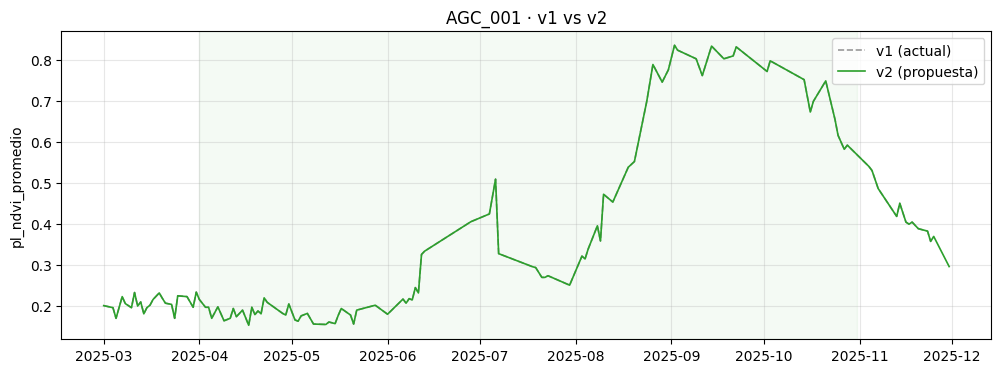

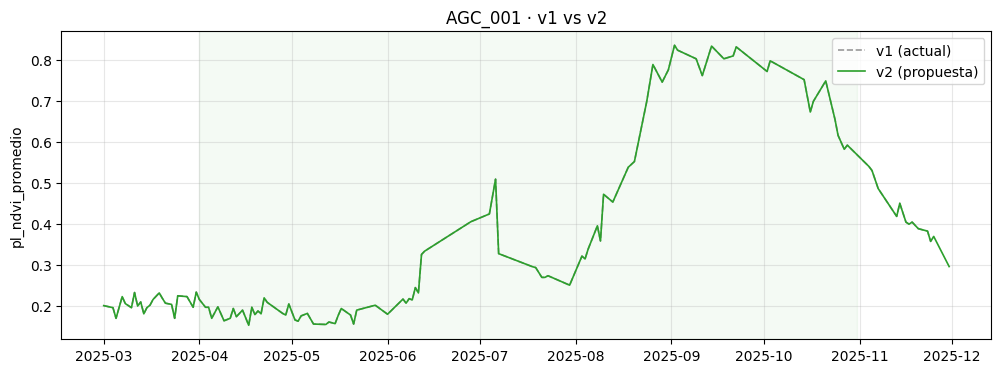

In [ ]:
def resumen_limpieza(d: pd.DataFrame)#estas son las metricas de calidad
    sin_dato = d["es_descartado"] & ~d["es_interpolado"]
    mes = d["fecha_captura"].dt.month
    return pd.Series({
        "atipicos_total": int(d["es_atipico"].sum()),
        "atipicos_marzo": int((d["es_atipico"] & mes.eq(3)).sum()),
        "atipicos_noviembre": int((d["es_atipico"] & mes.eq(11)).sum()),
        "sin_dato_ultima_semana": int((sin_dato & (d["fecha_captura"] >= "2025-11-24")).sum()),
        "pct_descartado": round(100 * d["es_descartado"].mean(), 1),
        "pct_interpolado": round(100 * d["es_interpolado"].mean(), 1),
        "pct_sin_rellenar": round(100 * sin_dato.mean(), 1),})
def features_ciclo(d: pd.DataFrame)
    ciclo = d[d["fecha_captura"].between("2025-04-01", "2025-10-31")]
    ciclo = ciclo.dropna(subset=["pl_ndvi_promedio"])
    grupos = ciclo.groupby(CLAVE)
    fila_max = grupos["pl_ndvi_promedio"].idxmax()
    fecha_max = pd.Series(
        ciclo.loc[fila_max.to_numpy(), "fecha_captura"].to_numpy(), index=fila_max.index)
    return pd.DataFrame({
        "ndvi_max": grupos["pl_ndvi_promedio"].max(),
        "ndvi_media": grupos["pl_ndvi_promedio"].mean(),
        "fecha_max": fecha_max,})
#de manera visual
def comparar_versiones(id_parcela: str)
    _, ax = plt.subplots(figsize=(12, 4))
    for datos, etiqueta, estilo in (
        (df_planet_v1, "v1 (actual)", dict(color="0.6", ls="--", lw=1.2)),
        (df_planet_v2, "v2 (propuesta)", dict(color="tab:green", lw=1.2)),):
        serie = datos[datos[CLAVE] == id_parcela]
        ax.plot(serie["fecha_captura"], serie["pl_ndvi_promedio"], label=etiqueta, **estilo)
    ax.axvspan(pd.Timestamp("2025-04-01"), pd.Timestamp("2025-10-31"), color="tab:green", alpha=0.05)
    ax.set_title(f"{id_parcela} · v1 vs v2")
    ax.set_ylabel("pl_ndvi_promedio")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
versiones = {
    "v1": df_planet_v1,
    "solo_borde": df_planet_borde,
    "solo_vecinos": df_planet_vecinos,
    "v2": df_planet_v2,}
print(pd.DataFrame({nombre: resumen_limpieza(d) for nombre, d in versiones.items()}))
f1, f2 = features_ciclo(df_planet_v1), features_ciclo(df_planet_v2)#los impactos si se ponen en el maestro
impacto = pd.DataFrame({
    "dif_ndvi_max": (f2["ndvi_max"] - f1["ndvi_max"]).abs(),
    "dif_ndvi_media": (f2["ndvi_media"] - f1["ndvi_media"]).abs(),
    "dif_fecha_max_dias": (f2["fecha_max"] - f1["fecha_max"]).dt.days.abs(),})
print("\nCambio absoluto por parcela (v1 → v2):")
print(impacto.describe(percentiles=[0.5, 0.9]).round(3))
print("\nParcelas con cambio de ndvi_max > 0.02:", impacto.index[impacto["dif_ndvi_max"] > 0.02].tolist())
print("Parcelas con fecha del pico movida > 7 días:", impacto.index[impacto["dif_fecha_max_dias"] > 7].tolist())
comparar_versiones(impacto["dif_fecha_max_dias"].idxmax())
comparar_versiones(impacto["dif_ndvi_max"].idxmax())

**componentes a visualizar AGC_001**:
Leyenda:

* **Ciclo abr–oct:** El área con fondo verde claro delimita el período oficial del ciclo agrícola evaluado.   
* **Serie limpia**: La línea gris continua muestra la trayectoria final de la serie temporal tras aplicar los procesos de depuración.   
* **Medido (121 en este ejemplo)**: Los puntos de color verde representan las 121 observaciones directas obtenidas por el sensor satelital.   
* **Interpolado (58 en este ejmplo)**: Los círculos anaranjados corresponden a los 58 puntos estimados mediante interpolación lineal para rellenar los vacíos de información.   
* **Atípico Hampel (1)**: La cruz de color morado ubicada cerca del mes de noviembre señala una anomalía detectada por el filtro estadístico de Hampel (un valor atípico o ruido que fue identificado y aislado).

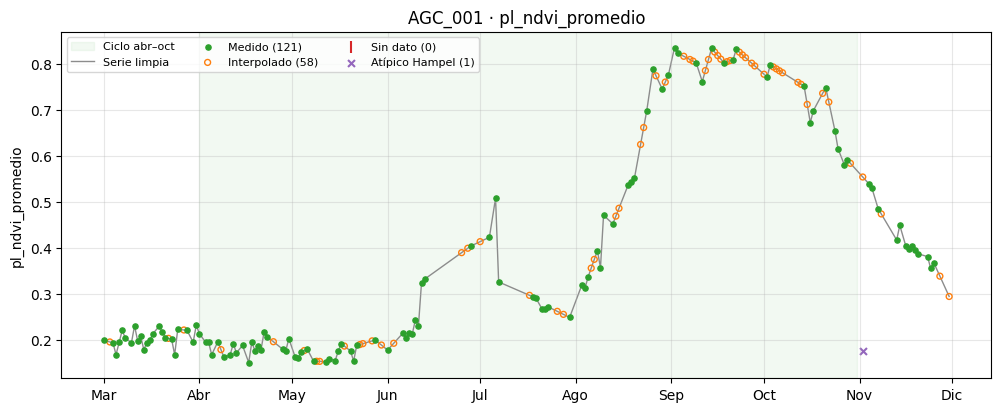

In [ ]:
MESES: list[str] = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
def graficar_parcela(
    df: pd.DataFrame,
    id_parcela: str,*,
    col_valor: str = "pl_ndvi_promedio",
    col_fecha: str = "fecha_captura",
    col_id: str = "id_poligono",
    inicio_ciclo: str = "2025-04-01",
    fin_ciclo: str = "2025-10-31",
    ax: Axes | None = None,)
    datos = df[df[col_id] == id_parcela].sort_values(col_fecha)
    if datos.empty:
        raise ValueError(f"La parcela {id_parcela!r} no está en el DataFrame.")
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 4.5))

    medido = ~datos["es_descartado"]
    interpolado = datos["es_interpolado"]
    sin_dato = datos["es_descartado"] & ~datos["es_interpolado"]
    fechas = datos[col_fecha]
#linea del cultivp
    ax.axvspan(pd.Timestamp(inicio_ciclo), pd.Timestamp(fin_ciclo),
               color="tab:green", alpha=0.06, label="Ciclo abr–oct")
    ax.plot(fechas, datos[col_valor], color="0.55", lw=1, zorder=1, label="Serie limpia")

    ax.scatter(fechas[medido], datos.loc[medido, col_valor], s=14,
               color="tab:green", zorder=3, label=f"Medido ({int(medido.sum())})")
    ax.scatter(fechas[interpolado], datos.loc[interpolado, col_valor], s=18,
               facecolors="none", edgecolors="tab:orange", zorder=2,
               label=f"Interpolado ({int(interpolado.sum())})")
#marcas en la base del gráfico (coordenada y relativa al eje: 0 = abajo)
    base = ax.get_xaxis_transform()
    ax.scatter(fechas[sin_dato], [0.03] * int(sin_dato.sum()), transform=base,
               marker="|", s=80, color="tab:red", label=f"Sin dato ({int(sin_dato.sum())})")
    if "es_atipico" in datos.columns:
        atipico = datos["es_atipico"]
        ax.scatter(fechas[atipico], [0.08] * int(atipico.sum()), transform=base,
                   marker="x", s=25, color="tab:purple",
                   label=f"Atípico Hampel ({int(atipico.sum())})")
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
    ax.set_title(f"{id_parcela} · {col_valor}")
    ax.set_ylabel(col_valor)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=8, ncols=3)
    return ax
graficar_parcela(df_planet, "AGC_001")
plt.show()

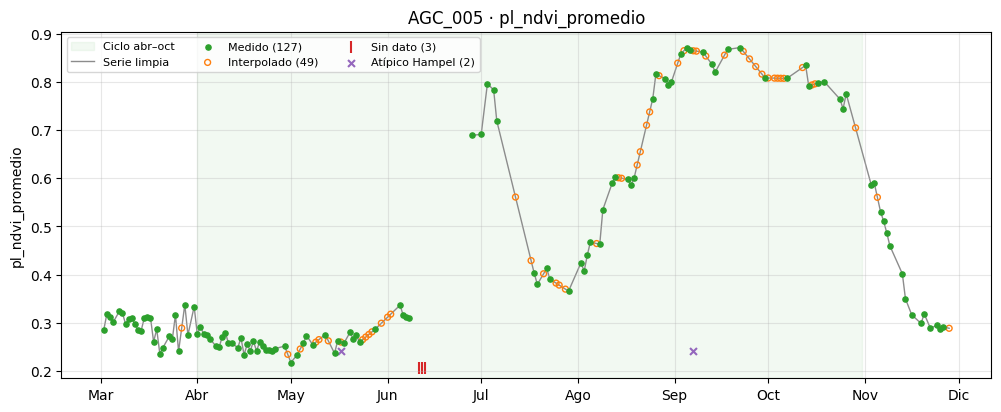

In [485]:
graficar_parcela(df_planet, "AGC_005")
plt.show()

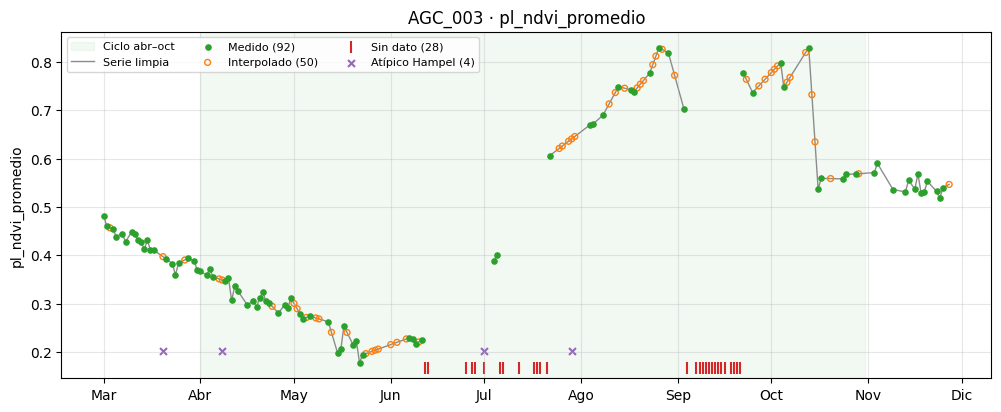

In [484]:
graficar_parcela(df_planet, "AGC_003")
plt.show()

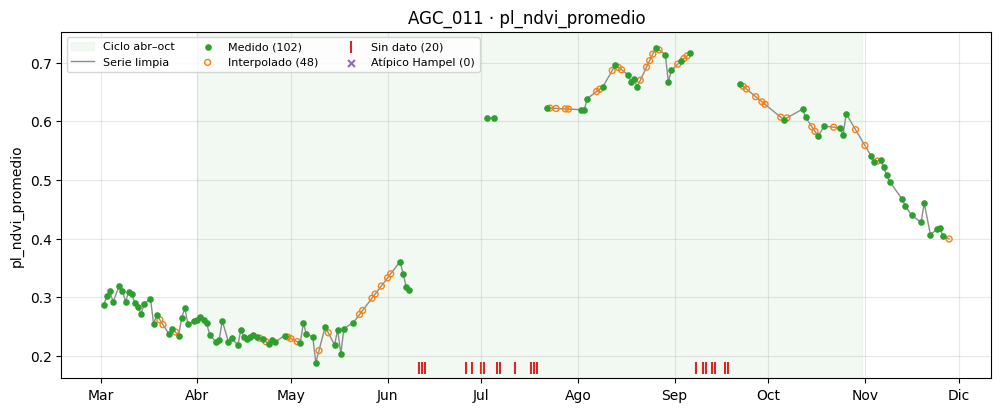

In [486]:
graficar_parcela(df_planet, "AGC_011")
plt.show()

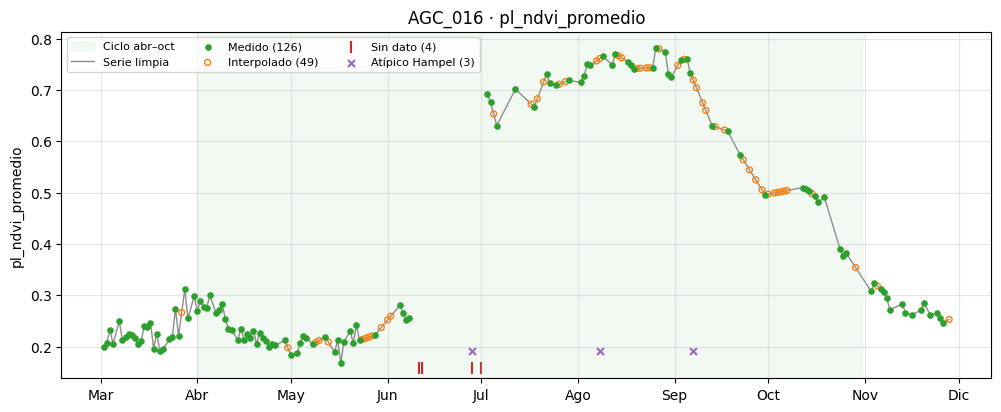

In [487]:
graficar_parcela(df_planet, "AGC_016")
plt.show()

In [ ]:
ciclo = df_planet[df_planet["fecha_captura"].between("2025-04-01", "2025-10-31")]
# 1) hora del analisis identifica donde marca Hampel? si hay muchas marcas en oct–nov, estara borrando cosechas
atipicos = df_planet[df_planet["es_atipico"]]
print("Atípicos de Hampel por mes:")
print(atipicos["fecha_captura"].dt.month.value_counts().sort_index())
# 2) caidas grandes que Hampel NO ppuso: un punto medido que queda más de 0.10 por debajo de sus dos vecinos medidos.
medidos = df_planet[~df_planet["es_descartado"]].copy()
grupo = medidos.groupby(CLAVE)["pl_ndvi_promedio"]
medidos["caida_vs_vecinos"] = (
    pd.concat([grupo.shift(1), grupo.shift(-1)], axis=1).min(axis=1)
    - medidos["pl_ndvi_promedio"])
sin_marcar = medidos[medidos["caida_vs_vecinos"] > 0.10]
print(f"\nCaídas aisladas > 0.10 sin marcar: {len(sin_marcar)} "
      f"en {sin_marcar[CLAVE].nunique()} parcelas")
print(sin_marcar[[CLAVE, "fecha_captura", "pl_ndvi_promedio", "caida_vs_vecinos"]].head(10))

# 3) parcelas con mas de un ciclo de verdor dentro de abr–oct (como AGC_005). ojo la funcion ignora los huecos
def contar_picos(serie: pd.Series, prominencia: float = 0.15)
    valores = serie.dropna().to_numpy()
    return len(find_peaks(valores, prominence=prominencia)[0]) if len(valores) > 5 else 0
picos = ciclo.groupby(CLAVE)["pl_ndvi_promedio"].apply(contar_picos)
print("\nParcelas por número de picos:")
print(picos.value_counts().sort_index())
print("Con 2 o más picos:", picos[picos >= 2].index.tolist())
# 4) Hueco más largo en la ventana crítica (jun–ago) por parcela.
critico = df_planet[df_planet["fecha_captura"].between("2025-06-01", "2025-08-31")]
hueco_max = critico.groupby(CLAVE)["hueco_dias"].max()
print("\nHueco máximo en jun–ago (días):")
print(hueco_max.describe(percentiles=[0.5, 0.9]).round(1))

Atípicos de Hampel por mes:
fecha_captura
3     19
4      5
5     10
6     58
7     67
8     23
9     35
10     6
11    14
Name: count, dtype: int64

Caídas aisladas > 0.10 sin marcar: 3 en 3 parcelas
      id_poligono fecha_captura  pl_ndvi_promedio  caida_vs_vecinos
4551      AGC_026    2025-09-07             0.539             0.109
14239     AGC_081    2025-09-13             0.641             0.105
22216     AGC_126    2025-10-07             0.615             0.107

Parcelas por número de picos:
pl_ndvi_promedio
0     15
1    145
2     34
3      3
Name: count, dtype: int64
Con 2 o más picos: ['AGC_001', 'AGC_003', 'AGC_005', 'AGC_025', 'AGC_028', 'AGC_029', 'AGC_030', 'AGC_040', 'AGC_056', 'AGC_057', 'AGC_066', 'AGC_068', 'AGC_071', 'AGC_072', 'AGC_086', 'AGC_091', 'AGC_093', 'AGC_098', 'AGC_099', 'AGC_110', 'AGC_111', 'AGC_116', 'AGC_117', 'AGC_126', 'AGC_135', 'AGC_136', 'AGC_141', 'AGC_143', 'AGC_150', 'AGC_155', 'AGC_157', 'AGC_163', 'AGC_167', 'AGC_169', 'AGC_172', 'AGC_181', '

# comparación de satelites planet y santinel

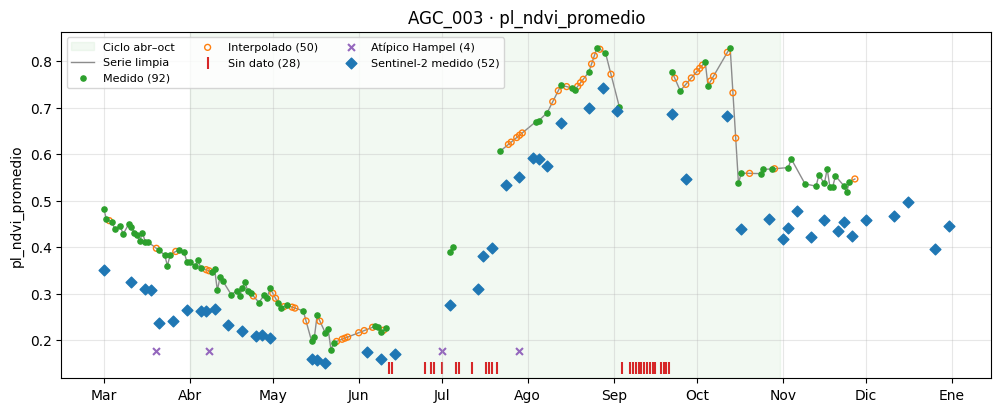

In [ ]:
pid = "AGC_003"
ax = graficar_parcela(df_planet, pid)
s2 = df_sentinel[
    (df_sentinel[CLAVE] == pid)
    & ~df_sentinel["es_descartado"]
    & df_sentinel["fecha_captura"].between("2025-03-01", "2025-12-31")]
ax.scatter(s2["fecha_captura"], s2["ndvi_promedio"], marker="D", s=30,
           color="tab:blue", zorder=4, label=f"Sentinel-2 medido ({len(s2)})")
ax.legend(loc="upper left", fontsize=8, ncols=3)
plt.show()

id_poligono
AGC_053    3
AGC_117    3
AGC_050    2
AGC_148    2
AGC_162    2
Name: es_descartado, dtype: int64


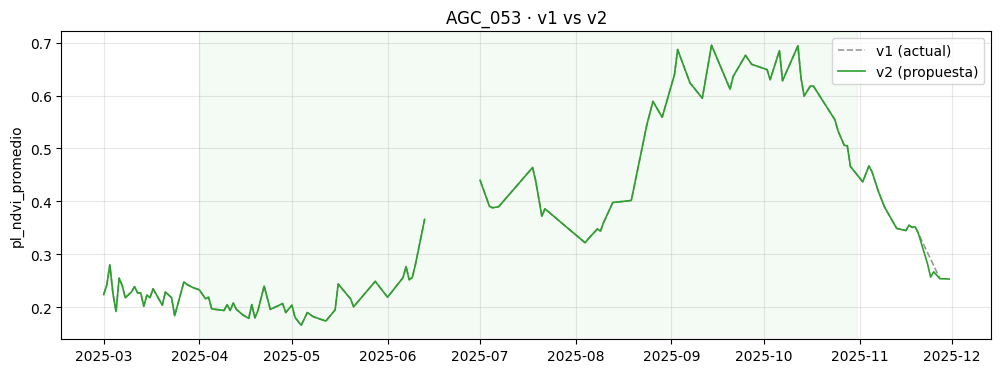

In [ ]:
cambio_mascara = (
    df_planet_v1.set_index([CLAVE, "fecha_captura"])["es_descartado"]
    != df_planet_v2.set_index([CLAVE, "fecha_captura"])["es_descartado"])
cambios_por_parcela = cambio_mascara.groupby(level=CLAVE).sum()
print(cambios_por_parcela.sort_values(ascending=False).head(5))
comparar_versiones(cambios_por_parcela.idxmax())

In [ ]:
df_planet = df_planet_v2  #ya se eligio la 2

**Anotaciones:**
se agrega las columnas es_atipico_hampel, es_atipico_vecinos y es_atipico
por ello so evalúa observaciones despejadas y con dato. No modifica valores: las marcas se aplican después mediante col_descarte_extra

In [ ]:
def marcar_atipicos(
    df: pd.DataFrame,
    *,
    col_referencia: str,
    umbral_nubes: float,
    max_dias_vecino: int = 10,
    ndvi_minimo_dosel: float | None = 0.30,
    col_id: str = CLAVE,
    col_fecha: str = "fecha_captura",)
    datos = df.sort_values([col_id, col_fecha]).reset_index(drop=True)
    nubes = datos["porcentaje_nubosidad"]
    despejadas = (nubes <= umbral_nubes) & nubes.notna() & datos[col_referencia].notna()
    columnas = dict(col_id=col_id, col_fecha=col_fecha, col_referencia=col_referencia)

    datos["es_atipico_hampel"] = marcar_caidas_hampel(datos, despejadas, **columnas)
    datos["es_atipico_vecinos"] = marcar_caidas_vecinos(
        datos, despejadas, max_dias_vecino=max_dias_vecino, **columnas)

    # solo se aceptaron marcas donde había dosel: en suelo desnudo, una caída de NDVI es ruido  que los índices de residuos necesitan conservar.
    if ndvi_minimo_dosel is not None:
        sub = datos.loc[despejadas, [col_id, col_referencia]]
        grupo = sub.groupby(col_id, sort=False)[col_referencia]
        vecino_max = pd.concat([grupo.shift(1), grupo.shift(-1)], axis=1).max(axis=1)
        en_dosel = pd.Series(False, index=datos.index)
        en_dosel.loc[sub.index] = (vecino_max >= ndvi_minimo_dosel).to_numpy()
        datos["es_atipico_hampel"] &= en_dosel
        datos["es_atipico_vecinos"] &= en_dosel
    datos["es_atipico"] = datos["es_atipico_hampel"] | datos["es_atipico_vecinos"]
    logger.info(
        "Atípicos — Hampel: %d | vecinos: %d | total: %d (%.1f %% de las despejadas)",
        int(datos["es_atipico_hampel"].sum()),
        int(datos["es_atipico_vecinos"].sum()),
        int(datos["es_atipico"].sum()),
        100 * datos["es_atipico"].sum() / max(int(despejadas.sum()), 1), )
    return datos

# Resumenes hasta el momento

In [ ]:
s2_crudo = df_ordenado[df_ordenado["sensor"] == "Sentinel-2"].dropna(how="all", axis=1)
ls_crudo = df_ordenado[df_ordenado["sensor"] == "Landsat"].dropna(how="all", axis=1)

parametros_s2 = dict(umbral_nubes=30, max_hueco_dias=30)
s2_v1 = filtrar_e_interpolar_pro(s2_crudo, **parametros_s2)
s2_v2 = filtrar_e_interpolar_pro(
    marcar_atipicos(s2_crudo, col_referencia="ndvi_promedio", umbral_nubes=30),
    **parametros_s2,
    col_descarte_extra="es_atipico",)
ls_v1 = filtrar_e_interpolar_pro(ls_crudo, umbral_nubes=30, max_hueco_dias=48)
   #NDVI máximo, medio y fecha del pico por parcela en abr–oct 2025
def features_ndvi(d: pd.DataFrame, col: str) 
    ciclo = d[d["fecha_captura"].between("2025-04-01", "2025-10-31")].dropna(subset=[col])
    grupos = ciclo.groupby(CLAVE)
    fila_max = grupos[col].idxmax()
    return pd.DataFrame({
        "ndvi_max": grupos[col].max(),
        "ndvi_media": grupos[col].mean(),
        "fecha_max": pd.Series(ciclo.loc[fila_max.to_numpy(), "fecha_captura"].to_numpy(),
                               index=fila_max.index),})



atipicos_2025 = s2_v2[s2_v2["es_atipico"] & s2_v2["fecha_captura"].dt.year.eq(2025)]
print("Atípicos S2 en 2025 por mes:")
print(atipicos_2025["fecha_captura"].dt.month.value_counts().sort_index())
f1, f2 = features_ndvi(s2_v1, "ndvi_promedio"), features_ndvi(s2_v2, "ndvi_promedio")
impacto = pd.DataFrame({
    "dif_ndvi_max": (f2["ndvi_max"] - f1["ndvi_max"]).abs(),
    "dif_ndvi_media": (f2["ndvi_media"] - f1["ndvi_media"]).abs(),
    "dif_fecha_max_dias": (f2["fecha_max"] - f1["fecha_max"]).dt.days.abs(),})
print("\nCambio por parcela (v1 → v2):")
print(impacto.describe(percentiles=[0.5, 0.9]).round(3))
print("Fecha del pico movida > 7 días:", impacto.index[impacto["dif_fecha_max_dias"] > 7].tolist())

INFO | Descartadas: 30.8 % | Interpoladas: 28.4 % | Sin rellenar: 2.4 %
INFO | Atípicos — Hampel: 214 | vecinos: 162 | total: 306 (0.7 % de las despejadas)
INFO | Descartadas: 31.3 % | Interpoladas: 28.9 % | Sin rellenar: 2.4 %
INFO | Descartadas: 41.5 % | Interpoladas: 39.3 % | Sin rellenar: 2.2 %


Atípicos S2 en 2025 por mes:
fecha_captura
1      1
2      1
3      1
6      2
7     37
8     29
9     30
10    25
11    10
12     1
Name: count, dtype: int64

Cambio por parcela (v1 → v2):
       dif_ndvi_max  dif_ndvi_media  dif_fecha_max_dias
count         197.0         197.000               197.0
mean            0.0           0.002                 0.0
std             0.0           0.003                 0.0
min             0.0           0.000                 0.0
50%             0.0           0.000                 0.0
90%             0.0           0.007                 0.0
max             0.0           0.015                 0.0
Fecha del pico movida > 7 días: []


antepone el prefijo del sensor a las columnas de índices (no a metadatos) ni a banderas

In [ ]:
COLS_NO_INDICE: set[str] = {
    CLAVE, "fecha_captura", "sensor", "porcentaje_nubosidad", "conjunto", "hueco_dias",}
def con_prefijo(df: pd.DataFrame, prefijo: str)
    indices = [
        c for c in df.select_dtypes("number").columns
        if c not in COLS_NO_INDICE and not c.startswith(prefijo)]
    return df.rename(columns={c: f"{prefijo}{c}" for c in indices})

s2_limpio = con_prefijo(unir_conjunto(s2_v2, gdf), "s2_")   # o s2_v1 si no aceptas la v2
ls_limpio = con_prefijo(unir_conjunto(ls_v1, gdf), "ls_")
pl_limpio = unir_conjunto(df_planet_v2, gdf)                  # ya trae el prefijo pl_

In [ ]:

DIR_INTERIM = Path.cwd() / "data" / "interim"
DIR_INTERIM.mkdir(parents=True, exist_ok=True)

series = {"s2": s2_limpio, "ls": ls_limpio, "pl": pl_limpio}
for nombre, datos in series.items():
    assert datos[CLAVE].nunique() == 197, f"{nombre}: faltan parcelas"
    assert datos["conjunto"].notna().all(), f"{nombre}: conjunto vacío"
    assert not datos.duplicated([CLAVE, "fecha_captura"]).any(), f"{nombre}: fechas duplicadas"
    assert (datos["es_interpolado"] <= datos["es_descartado"]).all(), nombre
    datos.to_parquet(DIR_INTERIM / f"{nombre}_limpio.parquet", index=False)
    print(f"{nombre}: {len(datos):,} filas, {datos.shape[1]} columnas → guardado")

s2: 59,040 filas, 101 columnas → guardado
ls: 48,626 filas, 14 columnas → guardado
pl: 34,828 filas, 29 columnas → guardado


# Resultados

 **Sentinel-2 (v2):**
 
 * filtro de nubes de 30 %, interpolación con un hueco máximo de 30 días y detección de caídas atípicas (Hampel con ventana de 21 días, más una caída mayor a 0.10 respecto a ambos vecinos a 10 días o menos). 
 * Las marcas solo se aceptan si algún vecino válido tiene NDVI ≥ 0.30. Sin esa condición, el 18 % de las marcas caía en suelo desnudo y se descartaban observaciones de labranza que los índices de residuos necesitan. 
 * Resultado: 306 marcas (0.7 % de las despejadas), concentradas en julio–octubre, sin cambio en ndvi_max ni en la fecha del pico. 
 * Landsat no lleva detección de atípicos: revisita cada 8 a 16 días, así que ninguno de los dos detectores tiene vecinos suficientes
 * Planet: queda con su versión aceptada la 2. para que  los dos sensores usen la misma condición de dosel por consistencia Su impacto sería solo sobre los 19 atípicos de marzo, que están fuera del ciclo.

In [ ]:

DIR_DATOS = Path(r"<ruta-local>\DATASET_RETO_AGRO_2026")
RUTA_RENDIMIENTO = DIR_DATOS / "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"   # ← ajusta el nombre real

rend = estandarizar_columnas(pd.read_csv(RUTA_RENDIMIENTO))
# Columnas sin nombre (se eliminan solo después de comprobar que están vacías.
sin_nombre = [c for c in rend.columns if c.startswith("unnamed")]
assert rend[sin_nombre].isna().all().all(), \
    f"Columnas sin nombre con datos: {rend[sin_nombre].dropna(how='all')}"
rend = rend.drop(columns=sin_nombre)

rend = rend.rename(columns={"area_ha": "area_ha_csv", "conjunto": "conjunto_csv"})
rend["conjunto_csv"] = rend["conjunto_csv"].astype("string").str.strip().str.upper()

# Si el CSV trae coma decimal ("3,5"), to_numeric lo convertiría en NaN sin avisar.
no_nulos = int(rend["rendimiento_t_ha"].notna().sum())
rend["rendimiento_t_ha"] = pd.to_numeric(rend["rendimiento_t_ha"], errors="coerce")
assert int(rend["rendimiento_t_ha"].notna().sum()) == no_nulos, \
    "Hay rendimientos no numéricos; revisa el separador decimal."
assert rend[CLAVE].is_unique and len(rend) == 197, "IDs duplicados o conteo distinto de 197"

print(rend.groupby("conjunto_csv")["rendimiento_t_ha"]
          .agg(filas="size", con_valor="count", minimo="min", mediana="median", maximo="max"))

               filas  con_valor  minimo  mediana  maximo
conjunto_csv                                            
ENTRENAMIENTO    138        138     2.0     4.34    5.59
PREDICCION        59          0     NaN      NaN     NaN


In [498]:
parcelas = gdf.rename(columns={"area_ha": "area_ha_shp"}).merge(
    rend, on=CLAVE, how="outer", validate="one_to_one", indicator=True
)

# 1) Cada ID debe existir en las dos fuentes.
sin_pareja = parcelas[parcelas["_merge"] != "both"]
assert sin_pareja.empty, f"IDs sin pareja:\n{sin_pareja[[CLAVE, '_merge']]}"
parcelas = parcelas.drop(columns=["_merge", "cultivo"])

# 2) CONJUNTO debe coincidir entre shapefile y CSV.
distinto = parcelas["conjunto"] != parcelas["conjunto_csv"]
assert not distinto.any(), f"CONJUNTO distinto:\n{parcelas.loc[distinto, [CLAVE, 'conjunto', 'conjunto_csv']]}"
parcelas = parcelas.drop(columns="conjunto_csv")

# 3) Anti-fuga: PREDICCION no puede tener rendimiento, aunque el CSV traiga 0 o relleno.
prediccion = parcelas["conjunto"].eq("PREDICCION")
print("PREDICCION con valor en el CSV:", int(parcelas.loc[prediccion, "rendimiento_t_ha"].notna().sum()))
parcelas.loc[prediccion, "rendimiento_t_ha"] = np.nan

# 4) ENTRENAMIENTO debe tener rendimiento completo y plausible.
entrenamiento = parcelas["conjunto"].eq("ENTRENAMIENTO")
assert entrenamiento.sum() == 138 and prediccion.sum() == 59
assert parcelas.loc[entrenamiento, "rendimiento_t_ha"].notna().all(), "Entrenamiento sin rendimiento"
fuera_rango = entrenamiento & ~parcelas["rendimiento_t_ha"].between(0.1, 10.0)
if fuera_rango.any():
    logger.warning("Rendimientos fuera de 0.1–10 t/ha: %s",
                   parcelas.loc[fuera_rango, [CLAVE, "rendimiento_t_ha"]].to_dict("records"))

PREDICCION con valor en el CSV: 0


In [499]:
from pyproj import Geod

assert parcelas.crs.to_epsg() == 4326, "El área geodésica requiere coordenadas geográficas"
_GEOD = Geod(ellps="WGS84")
parcelas["area_ha_geod"] = [
    abs(_GEOD.geometry_area_perimeter(g)[0]) / 10_000 for g in parcelas.geometry
]
parcelas["dif_area_shp_pct"] = 100 * (parcelas["area_ha_geod"] / parcelas["area_ha_shp"] - 1)
parcelas["dif_area_csv_pct"] = 100 * (parcelas["area_ha_geod"] / parcelas["area_ha_csv"] - 1)

print(parcelas[["area_ha_shp", "area_ha_csv", "area_ha_geod",
                "dif_area_shp_pct", "dif_area_csv_pct"]].describe().round(2))
print("Diferencia > 5 %:",
      parcelas.loc[parcelas["dif_area_shp_pct"].abs() > 5, CLAVE].tolist())

       area_ha_shp  area_ha_csv  area_ha_geod  dif_area_shp_pct  \
count       197.00       197.00        197.00            197.00   
mean          6.60         6.60          6.60             -0.01   
std           7.44         7.44          7.44              0.17   
min           0.35         0.35          0.35             -1.26   
25%           2.30         2.30          2.30             -0.05   
50%           5.46         5.46          5.46             -0.01   
75%           8.09         8.09          8.09              0.04   
max          64.30        64.30         64.30              0.53   

       dif_area_csv_pct  
count            197.00  
mean              -0.01  
std                0.17  
min               -1.26  
25%               -0.05  
50%               -0.01  
75%                0.04  
max                0.53  
Diferencia > 5 %: []


197 parcelas unidas por id_poligono entre el shapefile y el CSV de rendimiento, con validación uno a uno. 

CONJUNTO coincide en ambas fuentes. 

El área geodésica (WGS84) difiere menos de 1.3 % de las áreas reportadas, por redondeo. 

Se eliminaron cultivo (constante) y una columna vacía del CSV. 

El rendimiento de PREDICCION se fuerza a NaN como regla anti-fuga.

In [500]:
parcelas = parcelas.sort_values(CLAVE).reset_index(drop=True)
parcelas.to_parquet(DIR_INTERIM / "parcelas_base.parquet")                 # para Python
parcelas.to_file(DIR_INTERIM / "parcelas_base.gpkg", layer="parcelas_base")  # para QGIS
print(parcelas.shape, parcelas.columns.tolist())

INFO | Created 197 records


(197, 11) ['id_poligono', 'area_ha_shp', 'municipio', 'estado', 'conjunto', 'geometry', 'area_ha_csv', 'rendimiento_t_ha', 'area_ha_geod', 'dif_area_shp_pct', 'dif_area_csv_pct']


In [501]:
parcelas["rendimiento_t_ha"].value_counts().head()

rendimiento_t_ha
3.00    19
3.50    13
2.50    11
4.55     5
4.52     5
Name: count, dtype: int64

# RASTREADORES

Conexiones a los archivos tipo TIF:

In [ ]:
from exactextract import exact_extract

def buscar_unico(patron: str)#me lo encuentras
    encontrados = sorted(DIR_DATOS.rglob(patron))
    if len(encontrados) != 1:
        raise FileNotFoundError(f"'{patron}': {len(encontrados)} coincidencias → {encontrados}")
    return encontrados[0]
RUTA_ELEV = buscar_unico("Elevacion*.tif")
RUTA_PEND = buscar_unico("Pendiente*.tif")
print(RUTA_ELEV)
print(RUTA_PEND)
with rasterio.open(RUTA_ELEV) as src:
    crs_topo = src.crs
prueba = exact_extract(
    str(RUTA_ELEV),
    parcelas.to_crs(crs_topo).head(5),
    ["mean", "count"],
    include_cols=[CLAVE],
    output="pandas",)
print(prueba)

<ruta-local>\DATASET_RETO_AGRO_2026\Reto_AgroCebada_Topografia_INEGI_CEM4\Elevacion_INEGI_CEM4_120m.tif
<ruta-local>\DATASET_RETO_AGRO_2026\Reto_AgroCebada_Topografia_INEGI_CEM4\Pendiente_INEGI_CEM4_120m_grados.tif
  id_poligono         mean      count
0     AGC_001  2708.937487   5.255957
1     AGC_002  2611.461295   1.592665
2     AGC_003  2642.600950  12.881518
3     AGC_004  2564.199598   5.521540
4     AGC_005  2623.981209   1.567528


# Extracción zonal de topografía y clima

**Método.** Estadística zonal con exactextract, ponderada por la fracción de píxel cubierta.
El vector se reproyecta al CRS del ráster (nunca se remuestrea el ráster).

**Topografía (INEGI CEM, 120 m).** Elevación de 2,497 a 2,906 m; pendiente media de 0.3 a 9.4°.
- `diag_topo_pocos_pix`: 69 parcelas con < 2 píxeles efectivos (dispersión y máximos poco confiables).
- `diag_topo_nodata`: AGC_023, AGC_164 y AGC_170 (Calpulalpan y Apan), por NoData en el borde
  del DEM, confirmado con geometry_mask. La elevación media es válida; la pendiente de borde es dudosa.

**Clima (CHIRPS / CHIRTS, 0.05°).** 25 píxeles para 197 parcelas (r30c33 y r30c34 concentran el 48 %).
La temperatura se corrigió por elevación con un gradiente mensual por regresión T ~ z
(rango −10 a 0 °C/km, R² ≥ 0.5; respaldo = mediana de la variable: Tmax −2.76, Tmin −4.02).
Los 10 meses rechazados (Tmax, nov–mar) quedan fuera del ciclo. Corrección: Tmin −1.04 a +0.67 °C,
Tmax −0.78 a +0.50 °C. Ninguna parcela usa un píxel de clima con < 90 % de DEM válido.

**Auditoría.** 0 traslapes entre parcelas, 0 series duplicadas y 0 valores infinitos. Los índices fuera
de [−1, 1] son cocientes (STI, MSI, DSWI) o LAI. El LAI negativo (≥ −0.20) se recorta a 0 en el Paso 4.

**Variable objetivo.** 45 de 138 rendimientos (33 %) son múltiplos de 0.5, concentrados en
[municipios]. Se marcan con `diag_y_redondo` y `diag_y_resolucion` (nunca features).
En el modelado: error por grupo y pérdida robusta.

In [ ]:
registros = []
for ruta in sorted(DIR_DATOS.rglob("*.tif")):
    with rasterio.open(ruta) as src:
        registros.append({
            "archivo": ruta.stem,
            "carpeta": ruta.parent.name,          # "2022", "Tmax", "Reto_AgroCebada_Topografia_INEGI_CEM4"…
            "crs": src.crs.to_string() if src.crs else None,
            "res": round(src.res[0], 6),
            "dims": f"{src.width}x{src.height}",
            "nodata": src.nodata,
            "dtype": src.dtypes[0],
            "bandas": src.count,
            "bounds": tuple(round(b, 4) for b in src.bounds),
        })

inventario = pd.DataFrame(registros)
inventario["variable"] = inventario["archivo"].str.extract(r"^([A-Za-z]+)", expand=False)
inventario["periodo"] = inventario["archivo"].str.extract(r"(\d{4}_\d{2})$", expand=False)

# Resumen por variable: si una celda muestra más de un valor, hay rásteres inconsistentes ──
print("=== RESUMEN POR VARIABLE ===")
print(inventario.groupby("variable").agg(
    n=("archivo", "size"),
    crs=("crs", "unique"),
    res=("res", "unique"),
    dims=("dims", "unique"),
    nodata=("nodata", "unique"),
    dtype=("dtype", "unique"),
    bandas=("bandas", "unique"),
).to_string())

print(f"\nTotal de rásteres: {len(inventario)} (esperados: 146)")

# Meses completos de 2022-01 a 2025-12 en cada variable mensual 
print("\n=== COMPLETITUD TEMPORAL ===")
esperados = {f"{a}_{m:02d}" for a in range(2022, 2026) for m in range(1, 13)}
for var, grupo in inventario.dropna(subset=["periodo"]).groupby("variable"):
    faltan = sorted(esperados - set(grupo["periodo"]))
    duplicados = grupo["periodo"][grupo["periodo"].duplicated()].tolist()
    print(f"{var}: {len(grupo)} meses | faltantes: {faltan or 'ninguno'} | "
          f"duplicados: {duplicados or 'ninguno'}")

# Control cruzado: el año de la carpeta debe coincidir con el año del nombre 
mensuales = inventario.dropna(subset=["periodo"]).copy()
mensuales["anio_nombre"] = mensuales["periodo"].str[:4]
mal_ubicados = mensuales[mensuales["carpeta"] != mensuales["anio_nombre"]]
print("\nArchivos en carpeta de año equivocada:",
      mal_ubicados[["archivo", "carpeta"]].to_dict("records") or "ninguno")

=== RESUMEN POR VARIABLE ===
            n          crs      res         dims     nodata      dtype bandas
variable                                                                     
Elevacion   1  [EPSG:6372]  [120.0]  [2900x3362]  [-9999.0]  [float32]    [1]
PREC       48  [EPSG:4326]   [0.05]      [65x72]  [-9999.0]  [float32]    [1]
Pendiente   1  [EPSG:6372]  [120.0]  [2900x3362]  [-9999.0]  [float32]    [1]
Tmax       48  [EPSG:4326]   [0.05]      [65x72]  [-9999.0]  [float32]    [1]
Tmin       48  [EPSG:4326]   [0.05]      [65x72]  [-9999.0]  [float32]    [1]

Total de rásteres: 146 (esperados: 146)

=== COMPLETITUD TEMPORAL ===
PREC: 48 meses | faltantes: ninguno | duplicados: ninguno
Tmax: 48 meses | faltantes: ninguno | duplicados: ninguno
Tmin: 48 meses | faltantes: ninguno | duplicados: ninguno

Archivos en carpeta de año equivocada: ninguno


In [ ]:
# Sin agrupar por tuplas.
if "parcelas" not in globals():
    parcelas = gpd.read_parquet(DIR_INTERIM / "parcelas_base.parquet")
    print("parcelas recargada desde disco:", parcelas.shape)

print("=== COBERTURA DE PARCELAS ===")
inventario["bounds_txt"] = inventario["bounds"].astype(str)

for (crs, bounds_txt), grupo in inventario.groupby(["crs", "bounds_txt"]):
    bounds = grupo["bounds"].iloc[0]
    oeste, sur, este, norte = parcelas.to_crs(crs).total_bounds
    dentro = (bounds[0] <= oeste and bounds[1] <= sur
              and bounds[2] >= este and bounds[3] >= norte)
    print(f"{crs} | archivos: {len(grupo)} | variables: {grupo['variable'].unique().tolist()}")
    print(f"   ráster:   {bounds}")
    print(f"   parcelas: {tuple(round(float(b), 4) for b in (oeste, sur, este, norte))}")
    print(f"   parcelas dentro: {dentro}")

print("\nParcelas < 1.44 ha:", int((parcelas["area_ha_geod"] < 1.44).sum()))

=== COBERTURA DE PARCELAS ===
EPSG:4326 | archivos: 144 | variables: ['PREC', 'Tmax', 'Tmin']
   ráster:   (-99.95, 17.8, -96.7, 21.4)
   parcelas: (-98.613, 19.5238, -98.1967, 19.9844)
   parcelas dentro: True
EPSG:6372 | archivos: 2 | variables: ['Elevacion', 'Pendiente']
   ráster:   (2715840.0, 650400.0, 3063840.0, 1053840.0)
   parcelas: (2854345.4985, 840319.9953, 2896954.0829, 891715.7932)
   parcelas dentro: True

Parcelas < 1.44 ha: 18


In [ ]:
from exactextract import exact_extract
from rasterio.transform import rowcol
from rasterio.warp import Resampling, reproject

VARIABLES_CLIMA: dict[str, str] = {"PREC": "prec_mm", "Tmin": "tmin_c", "Tmax": "tmax_c"}

RUTA_ELEV = buscar_unico("Elevacion*.tif")
RUTA_PEND = buscar_unico("Pendiente*.tif")
RUTAS_CLIMA = [
    r for r in sorted(DIR_DATOS.rglob("*.tif")) if r.stem.split("_")[0] in VARIABLES_CLIMA
]
assert len(RUTAS_CLIMA) == 144, f"Se esperaban 144 rásteres de clima; hay {len(RUTAS_CLIMA)}"

if "parcelas" not in globals():
    parcelas = gpd.read_parquet(DIR_INTERIM / "parcelas_base.parquet")


def extraer_zonal(
    ruta: Path,
    poligonos: gpd.GeoDataFrame,
    operaciones: list[str],
    nombres: list[str],
) -> pd.DataFrame:
    """Estadística zonal ponderada por cobertura (exactextract) para un ráster.

    El vector se reproyecta al CRS del ráster: reproyectar polígonos solo
    transforma coordenadas, mientras que reproyectar el ráster lo remuestrea.

    Args:
        ruta: GeoTIFF de una banda, con NoData declarado.
        poligonos: Parcelas con ``CLAVE`` y geometría.
        operaciones: Operaciones de exactextract, p. ej. ``["mean", "count"]``.
        nombres: Nombre final de cada operación, en el mismo orden.

    Returns:
        DataFrame con ``CLAVE`` y una columna por operación.
    """
    if len(operaciones) != len(nombres):
        raise ValueError("Cada operación necesita un nombre.")
    with rasterio.open(ruta) as src:
        crs_raster = src.crs
    vector = poligonos[[CLAVE, "geometry"]].to_crs(crs_raster)
    resultado = exact_extract(str(ruta), vector, operaciones,
                              include_cols=[CLAVE], output="pandas")
    columnas_op = [c for c in resultado.columns if c != CLAVE]
    if len(columnas_op) != len(nombres):
        raise ValueError(f"exactextract devolvió {columnas_op}; se esperaban {len(nombres)} columnas.")
    return resultado.rename(columns=dict(zip(columnas_op, nombres)))

In [ ]:
#topografía por parcela: elevación, pendiente y calidad de cobertura.
elev = extraer_zonal(
    RUTA_ELEV, parcelas,
    ["mean", "stdev", "min", "max", "count"],
    ["elev_media_m", "elev_std_m", "elev_min_m", "elev_max_m", "topo_cobertura_pix"],)
pend = extraer_zonal(
    RUTA_PEND, parcelas,
    ["mean", "quantile(q=0.9)", "max", "count"],
    ["pend_media_grados", "pend_p90_grados", "pend_max_grados", "pend_cobertura_pix"],)
topo = elev.merge(pend, on=CLAVE, how="inner", validate="one_to_one")
# Contratos
assert len(topo) == 197 and not topo.isna().any().any(), "Topografía incompleta"
assert topo["elev_media_m"].between(1500, 3500).all(), "Elevaciones fuera de rango plausible"
assert "pend_cobertura_pix" in topo.columns, "Falta el count de la pendiente"
UMBRAL_NODATA: float = 0.98   # en el mismo plano, una parcela sana da ≈ 1.00
with rasterio.open(RUTA_ELEV) as src:
    crs_topo = src.crs
    area_pixel_ha = abs(src.res[0] * src.res[1]) / 10_000   # se lee del ráster, no se escribe a mano

# Área en el MISMO plano en que exactextract calcula la cobertura.
area_plano = pd.DataFrame({
    CLAVE: parcelas[CLAVE].to_numpy(),
    "_area_plano_ha": (parcelas.to_crs(crs_topo).area / 10_000).to_numpy(),
})
topo = topo.merge(area_plano, on=CLAVE, validate="one_to_one")
topo["ratio_cobertura_area"] = topo["topo_cobertura_pix"] * area_pixel_ha / topo["_area_plano_ha"]
topo["ratio_cobertura_pend"] = topo["pend_cobertura_pix"] / topo["topo_cobertura_pix"]

topo["diag_topo_pocos_pix"] = topo["topo_cobertura_pix"] < 2
# NoData en la elevación o un anillo extra de NoData en la pendiente (Horn 3×3).
topo["diag_topo_nodata"] = (
    (topo["ratio_cobertura_area"] < UMBRAL_NODATA)
    | (topo["ratio_cobertura_pend"] < UMBRAL_NODATA)
)
topo = topo.drop(columns="_area_plano_ha")

print("diag_topo_nodata:", topo.loc[topo["diag_topo_nodata"], CLAVE].tolist())
print(topo.describe().round(3).T[["min", "50%", "max"]])
print("Parcelas con < 2 píxeles efectivos:", int(topo["diag_topo_pocos_pix"].sum()))

diag_topo_nodata: ['AGC_020', 'AGC_023', 'AGC_164', 'AGC_170']
                           min       50%       max
elev_media_m          2496.648  2638.903  2906.040
elev_std_m               0.000     3.072    15.725
elev_min_m            2493.000  2630.000  2893.000
elev_max_m            2500.000  2647.000  2912.000
topo_cobertura_pix       0.243     3.765    44.351
pend_media_grados        0.282     2.126     9.396
pend_p90_grados          0.325     2.780    11.971
pend_max_grados          0.377     3.292    17.852
pend_cobertura_pix       0.118     3.455    44.351
ratio_cobertura_area     0.759     1.000     1.000
ratio_cobertura_pend     0.028     1.000     1.000
Parcelas con < 2 píxeles efectivos: 69


In [ ]:

partes = []
for ruta in RUTAS_CLIMA:
    variable, anio, mes = ruta.stem.split("_")
    tabla = extraer_zonal(ruta, parcelas, ["mean"], ["valor"])
    tabla["variable"] = VARIABLES_CLIMA[variable]
    tabla["anio"], tabla["mes"] = int(anio), int(mes)
    partes.append(tabla)

clima = (
    pd.concat(partes, ignore_index=True)
    # pivot (no pivot_table): si hubiera duplicados lanza error en lugar de promediarlos.
    .pivot(index=[CLAVE, "anio", "mes"], columns="variable", values="valor")
    .reset_index()
    .rename_axis(columns=None)
)

# Contratos.
assert len(clima) == 197 * 48, f"Se esperaban 9,456 filas; hay {len(clima)}"
assert not clima[["prec_mm", "tmin_c", "tmax_c"]].isna().any().any(), "Clima con NaN"
assert (clima["prec_mm"] >= 0).all(), "Precipitación negativa"
assert (clima["tmin_c"] < clima["tmax_c"]).all(), "Tmin ≥ Tmax en algún mes"

print(clima.groupby("mes")[["prec_mm", "tmin_c", "tmax_c"]].mean().round(1))

     prec_mm  tmin_c  tmax_c
mes                         
1       12.4     7.6    21.3
2       15.5     8.4    23.1
3       13.0    10.3    25.6
4       24.0    12.1    26.1
5       75.5    13.5    26.7
6      129.2    14.0    24.7
7      155.6    13.7    23.5
8      140.1    13.6    23.6
9      129.9    13.1    22.7
10      88.8    11.4    21.9
11      35.6     9.2    22.5
12      14.6     7.9    20.2


In [ ]:
#3.4
with rasterio.open(RUTAS_CLIMA[0]) as ref:
    transform_clima, crs_clima, forma_clima = ref.transform, ref.crs, ref.shape

# representative_point: siempre cae dentro del polígono (el centroide puede no hacerlo).
puntos = parcelas.to_crs(crs_clima).representative_point()
filas_px, columnas_px = rowcol(transform_clima, puntos.x.to_numpy(), puntos.y.to_numpy())
pixel = pd.DataFrame({
    CLAVE: parcelas[CLAVE].to_numpy(),
    "clima_pixel_id": [f"r{f:02d}c{c:02d}" for f, c in zip(filas_px, columnas_px)],})
por_pixel = pixel["clima_pixel_id"].value_counts()
print(f"Píxeles de clima distintos: {por_pixel.size} para 197 parcelas")
print("Parcelas por píxel (los 5 más poblados):")
print(por_pixel.head().to_string())

Píxeles de clima distintos: 25 para 197 parcelas
Parcelas por píxel (los 5 más poblados):
clima_pixel_id
r30c33    51
r30c34    44
r36c28    22
r36c27    11
r28c31    10


# Validación cruzada espacial
Por qué clima_pixel_id es valioso: además de servir como diagnóstico, en la fase de modelado se usa como grupo para la validación cruzada espacial. Si dos parcelas comparten píxel, comparten clima, y una no debe estar en entrenamiento mientras la otra está en validación. Si no se respeta esto, el error estimado sale optimista.

 **La función agregar_dem_a_malla:** Promedia el DEM de 120 m dentro de cada píxel de la malla de clima (0.05°).

    Resampling.average usa todos los píxeles finos que caen en cada píxel
    grueso e ignora el NoData del DEM.

In [522]:
#3.5
def agregar_dem_a_malla(ruta_dem: Path, ruta_referencia: Path, ruta_salida: Path) -> Path:
    """Promedia el DEM de 120 m dentro de cada píxel de la malla de clima (0.05°).

    Resampling.average usa todos los píxeles finos que caen en cada píxel
    grueso e ignora el NoData del DEM.
    """
    with rasterio.open(ruta_referencia) as ref:
        perfil = ref.profile.copy()
        destino = np.full(ref.shape, np.nan, dtype="float32")
        transform_ref, crs_ref = ref.transform, ref.crs

    with rasterio.open(ruta_dem) as dem:
        reproject(
            source=rasterio.band(dem, 1), destination=destino,
            src_transform=dem.transform, src_crs=dem.crs, src_nodata=dem.nodata,
            dst_transform=transform_ref, dst_crs=crs_ref, dst_nodata=np.nan,
            resampling=Resampling.average,
        )

    for clave in ("blockxsize", "blockysize", "tiled"):
        perfil.pop(clave, None)
    perfil.update(dtype="float32", nodata=np.nan, count=1)
    with rasterio.open(ruta_salida, "w", **perfil) as salida:
        salida.write(destino, 1)
    return ruta_salida


RUTA_DEM_MALLA = agregar_dem_a_malla(RUTA_ELEV, RUTAS_CLIMA[0], DIR_INTERIM / "dem_malla_clima.tif")

# Elevación media del (o de los) píxel(es) de clima que cubre cada parcela, con la
# misma ponderación que se usó para extraer la temperatura: así ambas son consistentes.
z_pixel = extraer_zonal(RUTA_DEM_MALLA, parcelas, ["mean"], ["z_pixel_clima_m"])
COLS_PIXEL: list[str] = ["z_pixel_clima_m", "clima_pixel_id", "dz_pixel_m"]
topo = (
    topo.drop(columns=COLS_PIXEL, errors="ignore")      # re-ejecutable
    .merge(z_pixel, on=CLAVE, validate="one_to_one")
    .merge(pixel, on=CLAVE, validate="one_to_one")
)
topo["dz_pixel_m"] = topo["elev_media_m"] - topo["z_pixel_clima_m"]
print(topo["dz_pixel_m"].describe().round(1))

count    197.0
mean      -8.9
std       60.1
min     -137.8
25%      -35.0
50%      -17.4
75%       11.8
max      213.5
Name: dz_pixel_m, dtype: float64


Se acepta cualquier gradiente negativo que la elevación explique bien (R² ≥ 0.5).
CHIRTS tiene gradientes más suaves que la atmósfera estándar (−6.5 °C/km), sobre todo en Tmax, así que el rango no debe imponer ese valor.

In [ ]:
RANGO_GRADIENTE: tuple[float, float] = (-10.0, 0.0)
R2_MINIMO: float = 0.5
MARGEN_GRADOS: float = 0.5                # vecindario alrededor de las parcelas (~50 km)

with rasterio.open(RUTA_DEM_MALLA) as src:
    z_malla = src.read(1)

# Centros de los píxeles de la malla de clima.
filas_i, columnas_i = np.indices(forma_clima)
x_centro = transform_clima.c + (columnas_i + 0.5) * transform_clima.a
y_centro = transform_clima.f + (filas_i + 0.5) * transform_clima.e

oeste, sur, este, norte = parcelas.to_crs(crs_clima).total_bounds
vecindario = (
    (x_centro >= oeste - MARGEN_GRADOS) & (x_centro <= este + MARGEN_GRADOS)
    & (y_centro >= sur - MARGEN_GRADOS) & (y_centro <= norte + MARGEN_GRADOS)
    & np.isfinite(z_malla)
)

#Pendiente de la regresión T ~ elevación (°C/km) en el vecindario de las parcelas
def estimar_gradiente(ruta: Path):
    with rasterio.open(ruta) as src:
        temperatura = src.read(1, masked=True).filled(np.nan)
    validos = vecindario & np.isfinite(temperatura)
    z_km, t = z_malla[validos] / 1000, temperatura[validos]
    pendiente, _ = np.polyfit(z_km, t, 1)
    r2 = float(np.corrcoef(z_km, t)[0, 1] ** 2)
    return {"gamma_c_km": float(pendiente), "r2": r2, "n_pixeles": int(validos.sum())}


filas_gradiente = []
for ruta in RUTAS_CLIMA:
    variable, anio, mes = ruta.stem.split("_")
    if variable == "PREC":
        continue
    filas_gradiente.append({"variable": VARIABLES_CLIMA[variable], "anio": int(anio),
                            "mes": int(mes), **estimar_gradiente(ruta)})

gradiente = pd.DataFrame(filas_gradiente)
gradiente["gradiente_aceptado"] = (
    gradiente["gamma_c_km"].between(*RANGO_GRADIENTE) & (gradiente["r2"] >= R2_MINIMO)
)
# Respaldo: mediana de los meses aceptados de la MISMA variable.
mediana_aceptada = (
    gradiente[gradiente["gradiente_aceptado"]].groupby("variable")["gamma_c_km"].median()
)
gradiente["gamma_usado"] = gradiente["gamma_c_km"].where(
    gradiente["gradiente_aceptado"], gradiente["variable"].map(mediana_aceptada)
)
gradiente.to_csv(DIR_INTERIM / "gradiente_termico.csv", index=False)

print(gradiente.groupby("variable")[["gamma_c_km", "r2"]].describe().round(2).T)
print("\nRespaldo por variable (°C/km):", mediana_aceptada.round(2).to_dict())
print("Meses rechazados por R² bajo (usan el respaldo):")
print(gradiente.loc[~gradiente["gradiente_aceptado"], ["variable", "anio", "mes", "gamma_c_km", "r2"]])

variable          tmax_c  tmin_c
gamma_c_km count   48.00   48.00
           mean    -2.14   -3.94
           std      1.05    0.59
           min     -3.66   -4.86
           25%     -3.03   -4.46
           50%     -2.17   -4.02
           75%     -1.28   -3.57
           max     -0.35   -2.62
r2         count   48.00   48.00
           mean     0.72    0.82
           std      0.27    0.10
           min      0.06    0.61
           25%      0.59    0.74
           50%      0.85    0.82
           75%      0.93    0.92
           max      0.98    0.96

Respaldo por variable (°C/km): {'tmax_c': -2.76, 'tmin_c': -4.02}
Meses rechazados por R² bajo (usan el respaldo):
   variable  anio  mes  gamma_c_km        r2
0    tmax_c  2022    1   -1.076522  0.478870
1    tmax_c  2022    2   -0.354224  0.060686
2    tmax_c  2022    3   -0.679071  0.326588
13   tmax_c  2023    2   -0.411603  0.150334
22   tmax_c  2023   11   -0.777549  0.281041
23   tmax_c  2023   12   -1.288472  0.417816
25   tma

In [ ]:
# Columnas base del clima: la celda puede re-ejecutarse sin acumular columnas.
COLS_CLIMA_BASE = [CLAVE, "anio", "mes", "prec_mm", "tmin_c", "tmax_c"]

faltan_topo = {"dz_pixel_m", "z_pixel_clima_m", "clima_pixel_id"} - set(topo.columns)
if faltan_topo:
    raise KeyError(f"A 'topo' le faltan {faltan_topo}: ejecuta las celdas 3.4 y 3.5 antes de esta.")
if "gamma_usado" not in gradiente.columns:
    raise KeyError("Ejecuta la celda 3.6 (gradiente) antes de esta.")

gamma_mes = (
    gradiente.pivot(index=["anio", "mes"], columns="variable", values="gamma_usado")
    .rename(columns={"tmin_c": "gamma_tmin_c_km", "tmax_c": "gamma_tmax_c_km"})
    .reset_index()
    .rename_axis(columns=None)
)

clima_final = (
    clima[COLS_CLIMA_BASE]
    .merge(topo[[CLAVE, "dz_pixel_m"]], on=CLAVE, how="left", validate="many_to_one")
    .merge(gamma_mes, on=["anio", "mes"], how="left", validate="many_to_one")
)
assert clima_final[["dz_pixel_m", "gamma_tmin_c_km", "gamma_tmax_c_km"]].notna().all().all()

dz_km = clima_final["dz_pixel_m"] / 1000
clima_final["tmin_c_ajust"] = clima_final["tmin_c"] + clima_final["gamma_tmin_c_km"] * dz_km
clima_final["tmax_c_ajust"] = clima_final["tmax_c"] + clima_final["gamma_tmax_c_km"] * dz_km
clima_final = clima_final.drop(columns="dz_pixel_m")   # vive en topo_parcela

assert len(clima_final) == 197 * 48
assert (clima_final["tmin_c_ajust"] < clima_final["tmax_c_ajust"]).all(), "Tmin ajustada ≥ Tmax ajustada"

print("Corrección aplicada (°C):")
print(pd.DataFrame({
    "tmin": clima_final["tmin_c_ajust"] - clima_final["tmin_c"],
    "tmax": clima_final["tmax_c_ajust"] - clima_final["tmax_c"],
}).describe().round(2))

clima_final = clima_final.sort_values([CLAVE, "anio", "mes"]).reset_index(drop=True)
topo = topo.sort_values(CLAVE).reset_index(drop=True)
clima_final.to_parquet(DIR_INTERIM / "clima_mensual_parcela.parquet", index=False)
topo.to_parquet(DIR_INTERIM / "topo_parcela.parquet", index=False)
print("Guardado:", clima_final.shape, topo.shape)

Corrección aplicada (°C):
          tmin     tmax
count  9456.00  9456.00
mean      0.04     0.02
std       0.24     0.16
min      -1.04    -0.78
25%      -0.04    -0.03
50%       0.07     0.04
75%       0.14     0.09
max       0.67     0.50
Guardado: (9456, 10) (197, 17)


In [ ]:
from shapely import union_all

revisar = (
    topo.loc[topo["ratio_cobertura_area"] < 0.97, [CLAVE, "ratio_cobertura_area", "topo_cobertura_pix"]]
    .merge(parcelas[[CLAVE, "area_ha_geod", "municipio", "conjunto"]], on=CLAVE)
)
print(revisar.to_string(index=False))

# ¿Partes traslapadas o huecos? Se mide en EPSG:6372 (metros).
for _, fila in parcelas[parcelas[CLAVE].isin(revisar[CLAVE])].to_crs("EPSG:6372").iterrows():
    partes = list(getattr(fila.geometry, "geoms", [fila.geometry]))
    suma_partes = sum(p.area for p in partes)
    area_union = union_all(partes).area
    print(f"{fila[CLAVE]} | {fila.geometry.geom_type} | partes: {len(partes)} | "
          f"huecos: {sum(len(p.interiors) for p in partes)} | "
          f"traslape: {100 * (1 - area_union / suma_partes):.1f} %")

id_poligono  ratio_cobertura_area  topo_cobertura_pix  area_ha_geod   municipio      conjunto
    AGC_023              0.958995            5.106799      7.716441 Calpulalpan ENTRENAMIENTO
    AGC_164              0.950612            7.765449     11.837268        Apan ENTRENAMIENTO
    AGC_170              0.759380            4.259916      8.128849 Calpulalpan ENTRENAMIENTO
AGC_023 | Polygon | partes: 1 | huecos: 0 | traslape: 0.0 %
AGC_164 | Polygon | partes: 1 | huecos: 0 | traslape: 0.0 %
AGC_170 | Polygon | partes: 1 | huecos: 0 | traslape: 0.0 %


In [526]:
#3.8b
from rasterio.features import geometry_mask
from rasterio.windows import from_bounds

with rasterio.open(RUTA_ELEV) as src:
    for pid in revisar[CLAVE]:
        geom = parcelas.loc[parcelas[CLAVE] == pid].to_crs(src.crs).geometry.iloc[0]
        ventana = from_bounds(*geom.buffer(240).bounds, transform=src.transform)
        ventana = ventana.round_offsets().round_lengths()
        datos = src.read(1, window=ventana)
        dentro = ~geometry_mask([geom], out_shape=datos.shape,
                                transform=src.window_transform(ventana), all_touched=True)
        sin_dato = dentro & (datos == src.nodata)
        print(f"{pid}: celdas que toca {int(dentro.sum())} | NoData {int(sin_dato.sum())}")

AGC_023: celdas que toca 13 | NoData 2
AGC_164: celdas que toca 16 | NoData 1
AGC_170: celdas que toca 14 | NoData 3


In [527]:
# 3.8c · Fracción de cada píxel de clima que el DEM cubre con dato válido.
with rasterio.open(RUTA_ELEV) as dem:
    valido = (dem.read(1) != dem.nodata).astype("float32")
    frac_dem = np.full(forma_clima, np.nan, dtype="float32")
    reproject(
        source=valido, destination=frac_dem,
        src_transform=dem.transform, src_crs=dem.crs,
        dst_transform=transform_clima, dst_crs=crs_clima, dst_nodata=np.nan,
        resampling=Resampling.average,
    )

frac_parcela = pd.Series(frac_dem[filas_px, columnas_px], index=parcelas[CLAVE].to_numpy())
print("Parcelas cuyo píxel de clima tiene < 90 % de DEM válido:")
print(frac_parcela[frac_parcela < 0.90].round(2).to_string())
print("Píxeles del vecindario del gradiente con < 90 %:",
      int((vecindario & (frac_dem < 0.90)).sum()), "de", int(vecindario.sum()))

Parcelas cuyo píxel de clima tiene < 90 % de DEM válido:
Series([], )
Píxeles del vecindario del gradiente con < 90 %: 57 de 694


In [528]:
# 3.9 · Calidad de la variable objetivo (diag_*: nunca features, dependen de y).
y = parcelas["rendimiento_t_ha"]
centesimas = (y * 100).round()

redondo = centesimas.mod(50).eq(0).astype("boolean")
redondo[y.isna()] = pd.NA                                   # PREDICCION: desconocido, no False
parcelas["diag_y_redondo"] = redondo

resolucion = np.select(
    [centesimas.mod(50).eq(0), centesimas.mod(10).eq(0)], [0.5, 0.1], default=0.01
)
parcelas["diag_y_resolucion"] = pd.Series(resolucion, index=parcelas.index).where(y.notna())

# Contratos.
assert parcelas.loc[parcelas["conjunto"].eq("PREDICCION"), "diag_y_redondo"].isna().all()
n_redondos = int(parcelas["diag_y_redondo"].sum())
print(f"Rendimientos múltiplos de 0.5: {n_redondos} de 138 ({n_redondos / 138:.0%})")
print(parcelas.loc[parcelas["diag_y_redondo"].fillna(False), "rendimiento_t_ha"]
      .value_counts().sort_index().to_string(), "\n")
# Coherencia geográfica: cada municipio debe pertenecer a un solo estado.
mpio_estado = parcelas.groupby("municipio")["estado"].agg(["nunique", "first"])
assert (mpio_estado["nunique"] == 1).all(), mpio_estado[mpio_estado["nunique"] > 1]
print(mpio_estado["first"].to_string(), "\n")

# ¿El heaping se concentra en algún municipio?
ent = parcelas[parcelas["conjunto"].eq("ENTRENAMIENTO")]
print(ent.groupby(["estado", "municipio"]).agg(
    n=(CLAVE, "size"),
    n_redondo=("diag_y_redondo", "sum"),
    pct_redondo=("diag_y_redondo", "mean"),
    y_mediana=("rendimiento_t_ha", "median"),
).round(2).to_string(), "\n")
print(pd.crosstab(ent["diag_y_resolucion"], ent["municipio"], margins=True), "\n")

# ¿Hay municipios con PREDICCION pero sin (o casi sin) ENTRENAMIENTO? → extrapolación.
print(pd.crosstab(parcelas["municipio"], parcelas["conjunto"], margins=True))

Rendimientos múltiplos de 0.5: 45 de 138 (33%)
rendimiento_t_ha
2.0     1
2.5    11
3.0    19
3.5    13
4.5     1 

municipio
Almoloya                          Hidalgo
Apan                              Hidalgo
Calpulalpan                      Tlaxcala
Chignahuapan                       Puebla
Cuautepec de Hinojosa             Hidalgo
Emiliano Zapata                   Hidalgo
Nanacamilpa de Mariano Arista    Tlaxcala
Singuilucan                       Hidalgo
Tepeapulco                        Hidalgo 

                                         n  n_redondo  pct_redondo  y_mediana
estado   municipio                                                           
Hidalgo  Almoloya                       10          0          0.0       4.53
         Apan                            1          1          1.0       3.00
         Cuautepec de Hinojosa           5          0          0.0       4.61
         Emiliano Zapata                 3          3          1.0       3.50
         Singuilucan      

ANALISIS DE ESTO AL LADO: -------->
REPORTE DE FEATURES:
SE extrae características agregadas y métricas fenológicas por parcela y por año a partir de las series temporales interpoladas

In [529]:
# 3.9 · Calidad de la variable objetivo (diag_*: nunca features, dependen de y).
y = parcelas["rendimiento_t_ha"]
centesimas = (y * 100).round()

redondo = centesimas.mod(50).eq(0).astype("boolean")
redondo[y.isna()] = pd.NA                                   # PREDICCION: desconocido, no False
parcelas["diag_y_redondo"] = redondo

resolucion = np.select(
    [centesimas.mod(50).eq(0), centesimas.mod(10).eq(0)], [0.5, 0.1], default=0.01
)
parcelas["diag_y_resolucion"] = pd.Series(resolucion, index=parcelas.index).where(y.notna())

# Contratos.
assert parcelas.loc[parcelas["conjunto"].eq("PREDICCION"), "diag_y_redondo"].isna().all()

# Conteo real de redondos (se mide, no se fija de antemano).
n_redondos = int(parcelas["diag_y_redondo"].sum())
print(f"Rendimientos múltiplos de 0.5: {n_redondos} de 138 ({n_redondos / 138:.0%})")
print(parcelas.loc[parcelas["diag_y_redondo"].fillna(False), "rendimiento_t_ha"]
      .value_counts().sort_index().to_string(), "\n")

# Coherencia geográfica: cada municipio debe pertenecer a un solo estado.
mpio_estado = parcelas.groupby("municipio")["estado"].agg(["nunique", "first"])
assert (mpio_estado["nunique"] == 1).all(), mpio_estado[mpio_estado["nunique"] > 1]
print(mpio_estado["first"].to_string(), "\n")

# ¿El heaping se concentra en algún municipio?
ent = parcelas[parcelas["conjunto"].eq("ENTRENAMIENTO")]
print(ent.groupby(["estado", "municipio"]).agg(
    n=(CLAVE, "size"),
    n_redondo=("diag_y_redondo", "sum"),
    pct_redondo=("diag_y_redondo", "mean"),
    y_mediana=("rendimiento_t_ha", "median"),
).round(2).to_string(), "\n")
print(pd.crosstab(ent["diag_y_resolucion"], ent["municipio"], margins=True), "\n")

# ¿Hay municipios con PREDICCION pero sin (o casi sin) ENTRENAMIENTO? → extrapolación.
print(pd.crosstab(parcelas["municipio"], parcelas["conjunto"], margins=True))

Rendimientos múltiplos de 0.5: 45 de 138 (33%)
rendimiento_t_ha
2.0     1
2.5    11
3.0    19
3.5    13
4.5     1 

municipio
Almoloya                          Hidalgo
Apan                              Hidalgo
Calpulalpan                      Tlaxcala
Chignahuapan                       Puebla
Cuautepec de Hinojosa             Hidalgo
Emiliano Zapata                   Hidalgo
Nanacamilpa de Mariano Arista    Tlaxcala
Singuilucan                       Hidalgo
Tepeapulco                        Hidalgo 

                                         n  n_redondo  pct_redondo  y_mediana
estado   municipio                                                           
Hidalgo  Almoloya                       10          0          0.0       4.53
         Apan                            1          1          1.0       3.00
         Cuautepec de Hinojosa           5          0          0.0       4.61
         Emiliano Zapata                 3          3          1.0       3.50
         Singuilucan      

In [ ]:
# Aditoría transversal del dataset (diagnóstico: no modifica datos).
# 1) Parcelas traslapadas. Si una de ENTRENAMIENTO se encima con una de PREDICCION, es la misma tierra con dos IDs → fuga de información.
p_plano = parcelas.to_crs(crs_topo)[[CLAVE, "conjunto", "geometry"]]
pares = gpd.sjoin(p_plano, p_plano, predicate="intersects")
pares = pares[pares[f"{CLAVE}_left"] < pares[f"{CLAVE}_right"]].copy()
geom_der = gpd.GeoSeries(
    p_plano.geometry.loc[pares["index_right"]].to_numpy(), index=pares.index, crs=p_plano.crs)
pares["traslape_ha"] = pares.geometry.intersection(geom_der).area / 10_000
traslapes = pares.loc[
    pares["traslape_ha"] > 0.01,
    [f"{CLAVE}_left", f"{CLAVE}_right", "conjunto_left", "conjunto_right", "traslape_ha"],]
print(f"Pares que solo se tocan: {len(pares) - len(traslapes)} | "
      f"con traslape > 0.01 ha: {len(traslapes)}")
print(traslapes.round(3).to_string(index=False), "\n")
# 2) Series idénticas en parcelas distintas (copias con otro ID).
firma = (
    pl_limpio.pivot(index="fecha_captura", columns=CLAVE, values="pl_ndvi_promedio")
    .round(4).T)
print("Parcelas con serie Planet idéntica a otra:",
      firma.index[firma.duplicated(keep=False)].tolist(), "\n")
# 3) Rangos físicos, infinitos y columnas casi vacías en los índices.
def auditar_indices(df: pd.DataFrame, prefijo: str) -> pd.DataFrame:
    """min/max, infinitos y % de NaN de las columnas de índices de un sensor."""
    num = df.filter(regex=f"^{prefijo}").select_dtypes("number")
    return pd.DataFrame({
        "min": num.min(),
        "max": num.max(),
        "n_inf": np.isinf(num).sum(),
        "pct_nan": 100 * num.isna().mean(),})
for prefijo, datos in {"s2_": s2_limpio, "ls_": ls_limpio, "pl_": pl_limpio}.items():
    aud = auditar_indices(datos, prefijo)
    sospechosas = aud[
        (aud["n_inf"] > 0) | (aud["min"] < -1) | (aud["max"] > 1) | (aud["pct_nan"] > 50)
    ]
    print(f"{prefijo}: {len(aud)} índices | sospechosos: {len(sospechosas)}")
    print(sospechosas.round(3).to_string(), "\n")

Pares que solo se tocan: 0 | con traslape > 0.01 ha: 0
Empty DataFrame
Columns: [id_poligono_left, id_poligono_right, conjunto_left, conjunto_right, traslape_ha]
Index: [] 

Parcelas con serie Planet idéntica a otra: [] 

s2_: 88 índices | sospechosos: 25
                     min    max  n_inf  pct_nan
s2_lai_promedio   -0.189  3.035      0    2.409
s2_lai_std         0.003  1.285      0    2.409
s2_lai_max        -0.170  9.513      0    2.409
s2_sti_promedio    1.007  2.509      0    2.409
s2_sti_max         1.091  6.550      0    2.409
s2_sti_min         0.401  2.103      0    2.409
s2_msi_promedio    0.282  2.171      0    2.409
s2_msi_max         0.446  3.897      0    2.409
s2_msi_min         0.067  1.579      0    2.409
s2_emsi_promedio   0.120  1.960      0    2.409
s2_emsi_max        0.215  4.745      0    2.409
s2_emsi_min        0.042  1.394      0    2.409
s2_dswi2_promedio  0.477  3.869      0    2.409
s2_dswi2_std       0.018  1.036      0    2.409
s2_dswi2_max       0.548

In [ ]:
#  contratos, guardado y relectura desde disco.
assert len(topo) == 197 and topo[CLAVE].is_unique
assert set(topo[CLAVE]) == set(parcelas[CLAVE]) == set(clima_final[CLAVE])
assert {"diag_topo_nodata", "diag_topo_pocos_pix", "clima_pixel_id", "dz_pixel_m"} <= set(topo.columns)
assert {"diag_y_redondo", "diag_y_resolucion"} <= set(parcelas.columns)

topo = topo.sort_values(CLAVE).reset_index(drop=True)
parcelas = parcelas.sort_values(CLAVE).reset_index(drop=True)
topo.to_parquet(DIR_INTERIM / "topo_parcela.parquet", index=False)
parcelas.to_parquet(DIR_INTERIM / "parcelas_base.parquet")
# GPKG no admite el booleano nulo de pandas: se pasa a float (1/0/NaN) solo para QGIS.
parcelas.assign(diag_y_redondo=parcelas["diag_y_redondo"].astype("float32")).to_file(
    DIR_INTERIM / "parcelas_base.gpkg", layer="parcelas_base")
ESPERADOS: dict[str, int | None] = {
    "parcelas_base.parquet": 197,
    "parcelas_base.gpkg": None,
    "s2_limpio.parquet": 59_040,
    "ls_limpio.parquet": 48_626,
    "pl_limpio.parquet": 34_828,
    "topo_parcela.parquet": 197,
    "clima_mensual_parcela.parquet": 9_456,
    "gradiente_termico.csv": 96,
    "dem_malla_clima.tif": None,}
for nombre, filas in ESPERADOS.items():
    ruta = DIR_INTERIM / nombre
    assert ruta.exists(), f"Falta {nombre}"
    if filas is not None:
        leido = pd.read_csv(ruta) if ruta.suffix == ".csv" else pd.read_parquet(ruta)
        assert len(leido) == filas, f"{nombre}: {len(leido)} filas (esperadas {filas})"
    print(f"OK  {nombre:32s} {ruta.stat().st_size / 1e6:7.2f} MB")

INFO | Created 197 records


OK  parcelas_base.parquet               0.13 MB
OK  parcelas_base.gpkg                  0.26 MB
OK  s2_limpio.parquet                  11.15 MB
OK  ls_limpio.parquet                   0.59 MB
OK  pl_limpio.parquet                   1.58 MB
OK  topo_parcela.parquet                0.03 MB
OK  clima_mensual_parcela.parquet       0.26 MB
OK  gradiente_termico.csv               0.01 MB
OK  dem_malla_clima.tif                 0.01 MB


# CONCLUSIONES 
Primera etapa del **Preprocesamiento y Limpieza de Datos** debido al tamaño del notebook y el riesgo a presnetar fallas tecnicas al correr todos los comandos de corrido, esta limpieza es para series temporales satelitales y climáticas enfocadas en el Reto AgroCebada 2026. A partir del código e información provista, se desprenden las siguientes conclusiones principales:

* **Homologación y Estandarización Estructural**: Se implementaron funciones para transformar los nombres de las columnas a formato *snake_case* y validar identificadores de parcela únicos (`id_poligono`), previniendo errores de sintaxis y colisiones de variables (*data leakage*) al cruzar fuentes satelitales y climáticas.


* **Control de Calidad Espacial y Tabular**: El primer conjunto de datos evaluado (`Parcelas_Reto_AGC_CONJUNTO.shp`) contiene 197 registros con geometrías válidas y sin nulos, abarcando los estados de Puebla, Hidalgo y Tlaxcala, divididos en conjuntos de entrenamiento y predicción.


* **Estrategia de Manejo de Nubosidad**: Se descartó la eliminación directa de datos nublados en favor de un **filtrado por enmascaramiento e interpolación temporal**, evitando perder la dimensionalidad y continuidad de las series temporales. Las observaciones con más del 30% de nubosidad se enmascararon y se interpolaron con un límite de ventana máxima (por ejemplo, 30 días para Sentinel-2 y 48 días para Landsat).


* **Detección Robusta de Anomalías (Filtro de Hampel y Vecinos)**: Para refinar los índices de vegetación (como el NDVI) y eliminar ruido residual o sombras finas sin alterar las caídas reales por cosecha, se integró el filtro de Hampel (basado en la desviación absoluta de la mediana) y un detector de caídas por vecindad temporal.


* **Validación de Versiones**: Las pruebas comparativas entre distintas iteraciones metodológicas demostraron que recortar la ventana temporal al final del proceso e incorporar detectores estadísticos avanzados (como Hampel y vecinos) permite preservar de manera óptima las métricas fenológicas críticas (como el NDVI máximo del ciclo agrícola y su fecha de ocurrencia) sin alterar los parámetros clave.
